In [ ]:
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.multioutput import MultiOutputRegressor
import math
from scipy.spatial.distance import mahalanobis
from scipy.stats import chi2
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

#EDA

In [ ]:
#get helper functions
%run '/content/drive/MyDrive/Colab Notebooks/RCC_Beam_Optimization/helper_functions.ipynb'


In [ ]:
param_ranges

{'b': (200.0, 500.0), 'd': (300.0, 1500.0), 'Ast': (200.0, 10000.0)}

In [ ]:
# Load dataset
df = pd.read_csv("ensemble_best_designs_1029.csv")
df.head()

,fck,fy,Mu,b,d,Ast,algorithm,is_valid,cost,MOR,Mul,utilization,rho,bd_ratio
0,20,415,40,200,301,434.8,PSO,True,1380.85,40.133,50.048,0.9967,0.0072,0.664
1,20,415,60,201,347,584.4,DE,True,1688.46,60.419,66.847,0.9931,0.0084,0.579
2,20,415,80,201,387,709.0,SA,True,1946.00,80.230,83.146,0.9971,0.0091,0.519
3,20,415,100,200,442,764.9,PSO,True,2166.63,100.033,107.923,0.9997,0.0087,0.452
4,20,415,120,201,477,858.5,SA,True,2381.65,120.234,126.316,0.9981,0.0090,0.421


In [ ]:
df.describe()

,fck,fy,Mu,b,d,Ast,cost,MOR,Mul,utilization,rho,bd_ratio
count,1029.000000,1029.000000,1029.000000,1029.000000,1029.000000,1029.000000,1029.000000,1029.000000,1029.000000,1029.000000,1029.000000,1029.000000
mean,35.000000,488.333333,520.000000,230.263362,712.199223,1935.786686,4662.110991,520.911005,575.220574,0.998009,0.011384,0.342060
std,10.004863,55.754610,282.980248,32.047230,180.765520,838.420659,1771.224203,283.328806,291.287090,0.001462,0.002945,0.091167
min,20.000000,415.000000,40.000000,200.000000,300.000000,294.700000,1223.880000,40.000000,46.870000,0.986000,0.004900,0.300000
25%,25.000000,415.000000,280.000000,201.000000,624.000000,1215.500000,3232.970000,280.428000,343.001000,0.997500,0.009400,0.301000
50%,35.000000,500.000000,520.000000,221.000000,734.000000,1965.700000,4726.750000,520.890000,567.013000,0.998300,0.011100,0.301000
75%,45.000000,550.000000,760.000000,253.000000,839.000000,2592.600000,6118.930000,761.526000,813.481000,0.998900,0.013900,0.322000
max,50.000000,550.000000,1000.000000,326.000000,1086.000000,3747.400000,8689.400000,1002.574000,1390.411000,1.000000,0.018000,0.670000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1029 entries, 0 to 1028
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   fck          1029 non-null   int64  
 1   fy           1029 non-null   int64  
 2   Mu           1029 non-null   int64  
 3   b            1029 non-null   int64  
 4   d            1029 non-null   int64  
 5   Ast          1029 non-null   float64
 6   algorithm    1029 non-null   object 
 7   is_valid     1029 non-null   bool   
 8   cost         1029 non-null   float64
 9   MOR          1029 non-null   float64
 10  Mul          1029 non-null   float64
 11  utilization  1029 non-null   float64
 12  rho          1029 non-null   float64
 13  bd_ratio     1029 non-null   float64
dtypes: bool(1), float64(7), int64(5), object(1)
memory usage: 105.6+ KB


In [ ]:
duplicates = df.duplicated().sum()
print(duplicates)

0


In [ ]:
print("🧹 Missing Values:")
print(df.isnull().sum())

🧹 Missing Values:
fck            0
fy             0
Mu             0
b              0
d              0
Ast            0
algorithm      0
is_valid       0
cost           0
MOR            0
Mul            0
utilization    0
rho            0
bd_ratio       0
dtype: int64


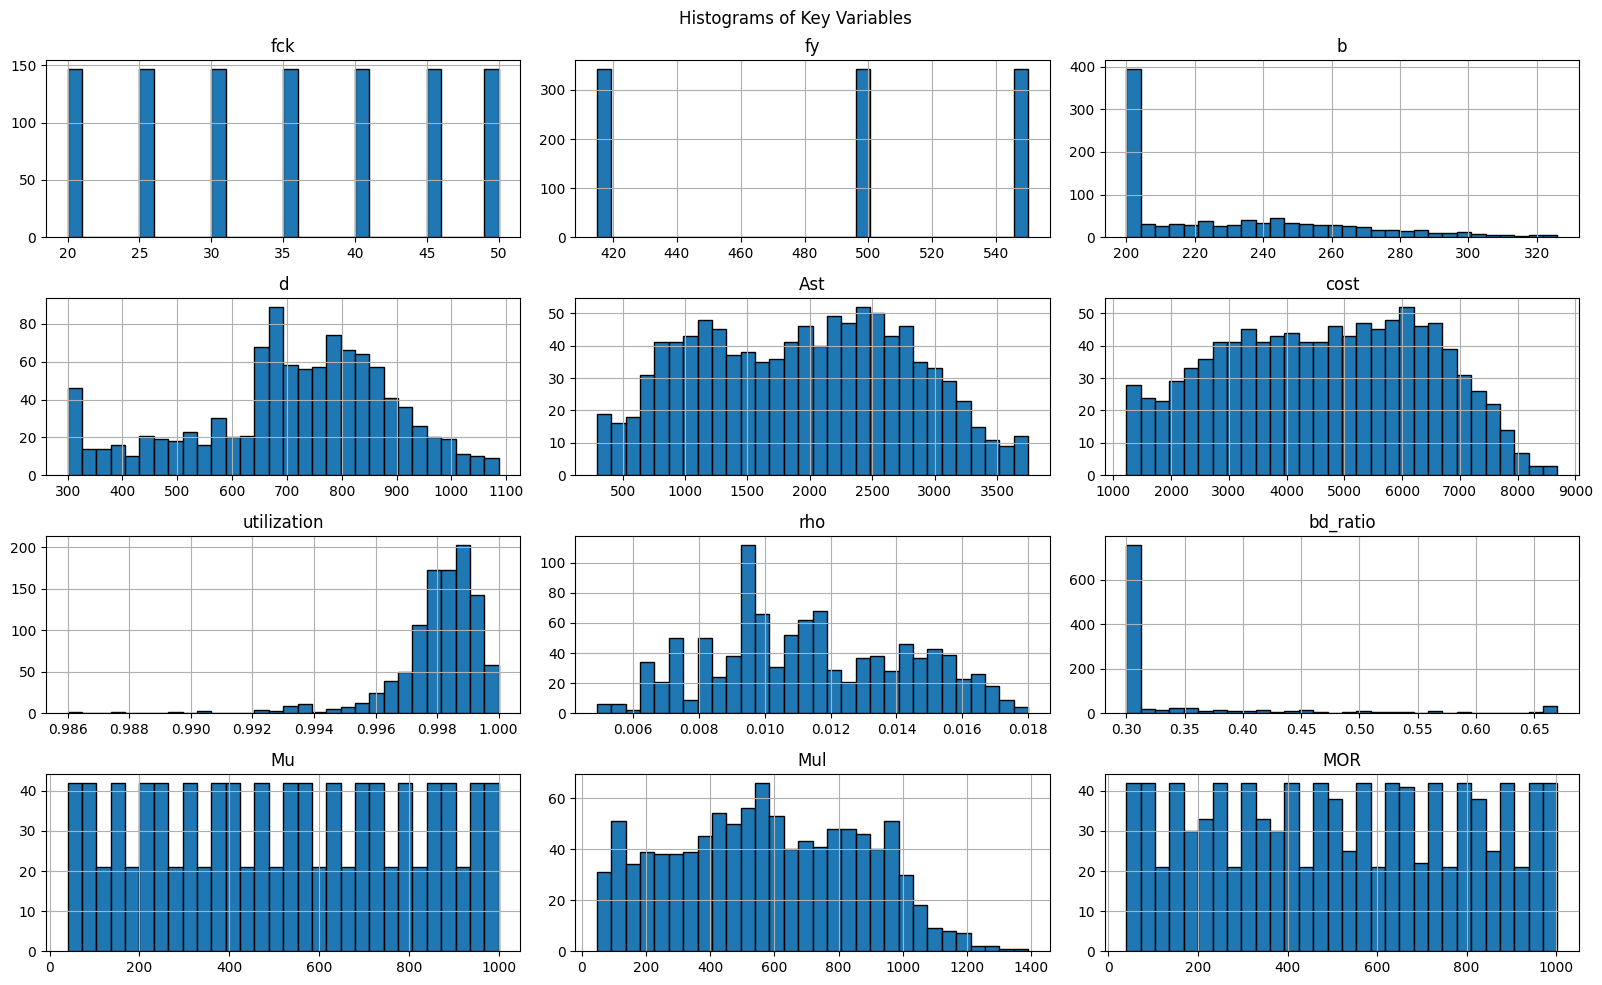

In [ ]:
# Distribution of numerical variables
numeric_cols = ['fck','fy', 'b', 'd', 'Ast',  'cost', 'utilization', 'rho', 'bd_ratio', 'Mu', 'Mul', 'MOR']
df[numeric_cols].hist(bins=30, figsize=(16, 10), edgecolor='black')
plt.suptitle("Histograms of Key Variables")
plt.tight_layout()
plt.show()

In [ ]:
df1 = df.drop(columns=['algorithm', 'is_valid', 'MOR', 'Mul', 'bd_ratio'], inplace=False)

In [ ]:
df1.describe()

,fck,fy,Mu,b,d,Ast,cost,utilization,rho
count,1029.000000,1029.000000,1029.000000,1029.000000,1029.000000,1029.000000,1029.000000,1029.000000,1029.000000
mean,35.000000,488.333333,520.000000,230.263362,712.199223,1935.786686,4662.110991,0.998009,0.011384
std,10.004863,55.754610,282.980248,32.047230,180.765520,838.420659,1771.224203,0.001462,0.002945
min,20.000000,415.000000,40.000000,200.000000,300.000000,294.700000,1223.880000,0.986000,0.004900
25%,25.000000,415.000000,280.000000,201.000000,624.000000,1215.500000,3232.970000,0.997500,0.009400
50%,35.000000,500.000000,520.000000,221.000000,734.000000,1965.700000,4726.750000,0.998300,0.011100
75%,45.000000,550.000000,760.000000,253.000000,839.000000,2592.600000,6118.930000,0.998900,0.013900
max,50.000000,550.000000,1000.000000,326.000000,1086.000000,3747.400000,8689.400000,1.000000,0.018000


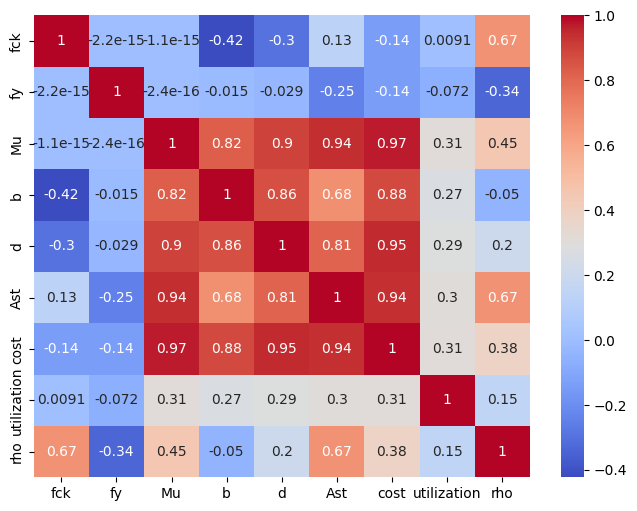

In [ ]:
# Correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(df1.corr(), annot=True, cmap='coolwarm')
plt.show()

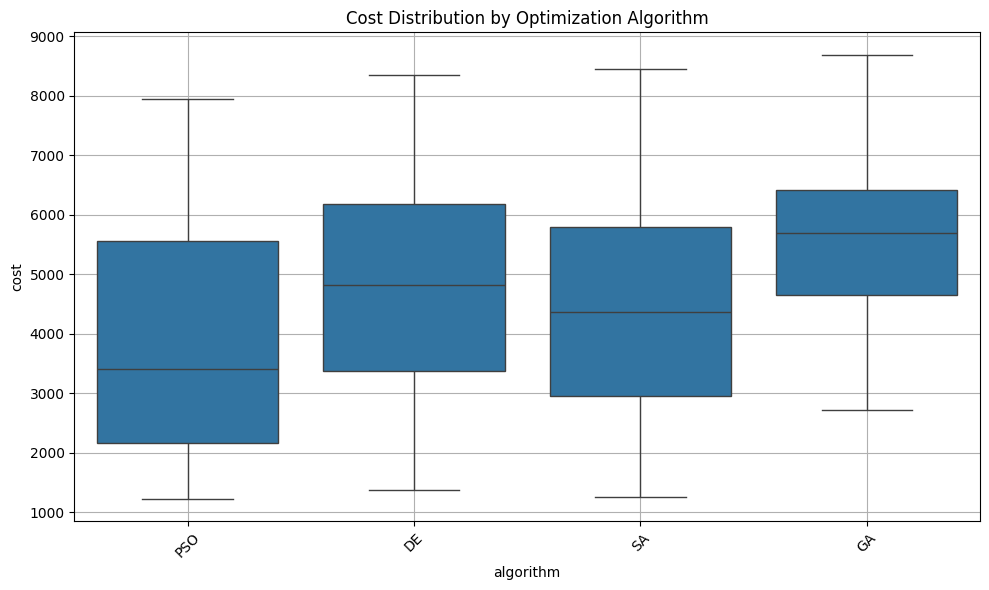

In [ ]:
# Boxplot of cost by algorithm
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='algorithm', y='cost')
plt.title("Cost Distribution by Optimization Algorithm")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

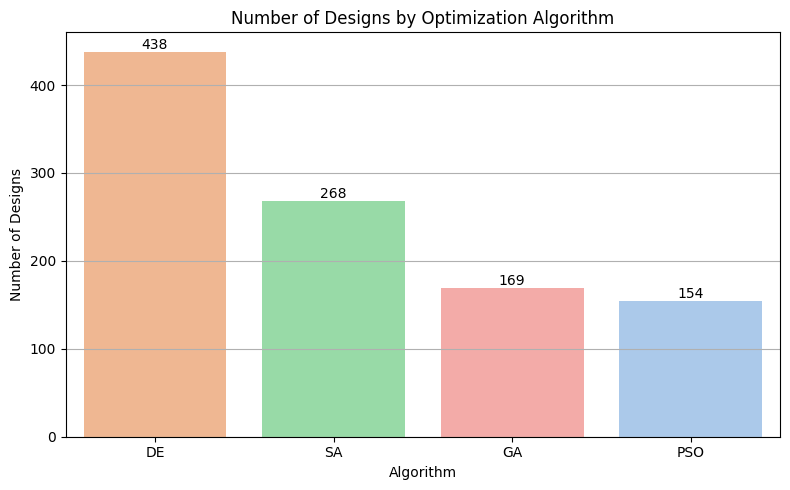

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='algorithm', hue='algorithm',
                   order=df['algorithm'].value_counts().index,
                   palette='pastel', legend=False)

# Optional: annotate counts
for p in ax.patches:
    ax.annotate(f'{round(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10)

plt.title("Number of Designs by Optimization Algorithm")
plt.xlabel("Algorithm")
plt.ylabel("Number of Designs")
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.tight_layout()
plt.show()


#Training

##Prelims

In [ ]:
# Load and filter dataset
df = pd.read_csv("ensemble_best_designs_1029.csv")

# === Define features and targets ===
X = df[['fck', 'fy', 'Mu']].values
y = df[['b', 'd', 'Ast']].values
X.shape, y.shape

((1029, 3), (1029, 3))

In [ ]:
# === Split ===
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [ ]:
def print_accuracy(y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    print(f"R²: {r2:.4f}, RMSE: {rmse:.2f}")

def get_accuracy(y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    return round(r2,4),  round(rmse,4)

def get_cost_accuracy(cost_true, cost_pred):
    cost_accuracy = 1 - abs(cost_pred - cost_true) / cost_true
    return cost_accuracy

def get_costs_accuracy(costs_true, costs_pred):
    cost_accuracy = np.mean([get_cost_accuracy(true, pred) for true, pred in zip(costs_true, costs_pred)])
    return np.round(cost_accuracy,4)

def evaluate_model(y_test, y_pred, target_names=['b', 'd', 'Ast']):
    for i, name in enumerate(target_names):
        r2 = r2_score(y_test[:, i], y_pred[:, i])
        rmse = root_mean_squared_error(y_test[:, i], y_pred[:, i])
        print(f"{name}: R² = {r2:.4f}, RMSE = {rmse:.2f}")

    costs_true = [get_cost(b,d,Ast) for b,d,Ast in zip(y_test[:,0], y_test[:,1], y_test[:,2])]
    costs_pred = [get_cost(b,d,Ast) for b,d,Ast in zip(y_pred[:,0], y_pred[:,1], y_pred[:,2])]

    print("Cost accuracy:", get_costs_accuracy(costs_true, costs_pred))


def plot_predictions(y_test, y_pred, target_names=['b', 'd', 'Ast'], model="LR"):
    for i, name in enumerate(target_names):
        # Accuracy metrics
        r2, rmse = get_accuracy(y_test[:, i], y_pred[:, i])
        textstr = f"R² = {r2:.4f}\nRMSE = {rmse:.2f}"

        plt.figure(figsize=(5, 4))
        plt.scatter(y_test[:, i], y_pred[:, i], alpha=0.6)
        plt.plot([y_test[:, i].min(), y_test[:, i].max()],
                 [y_test[:, i].min(), y_test[:, i].max()],
                 'r--', label='Ideal')
        plt.gca().text(0.05, 0.95, textstr, transform=plt.gca().transAxes,
                        verticalalignment='top',
                       bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))
        plt.xlabel(f"Actual {name}")
        plt.ylabel(f"Predicted {name}")
        plt.title(f"{model}: Actual vs Predicted {name}")
        plt.grid(True)
        plt.legend()
        plt.tight_layout()
        plt.show()

def plot_costs(costs_actual, costs_pred):
    plt.figure(figsize=(5, 4))
    plt.scatter(costs_actual, costs_pred, alpha=0.6)
    min_val = min(min(costs_actual), min(costs_pred))
    max_val = max(max(costs_actual), max(costs_pred))
    plt.plot([min_val, max_val], [min_val, max_val], 'r--', label='Ideal')
    plt.xlabel("Actual costs")
    plt.ylabel("Predicted costs")
    plt.title("Actual vs Predicted costs")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [ ]:
def plot_predictions_validity(y_test, y_pred, X_test, target_names=['b', 'd', 'Ast'], model="LR", saveas="figure1"):
    for i, name in enumerate(target_names):
        plt.figure(figsize=(5, 4))

        valid_x = []
        valid_y = []
        invalid_x = []
        invalid_y = []

        all_x = []
        all_y = []

        for j in range(len(y_pred)):
            b, d, Ast = y_pred[j]
            fck, fy, Mu = X_test[j]

            x_val = y_test[j, i]
            y_val = y_pred[j, i]

            all_x.append(x_val)
            all_y.append(y_val)

            if is_valid_design(b, d, Ast, fck, fy, Mu):
                valid_x.append(x_val)
                valid_y.append(y_val)
            else:
                invalid_x.append(x_val)
                invalid_y.append(y_val)

        # Scatter plots
        plt.scatter(valid_x, valid_y, alpha=0.6, label='Valid Design', color='blue')
        plt.scatter(invalid_x, invalid_y, alpha=0.6, label='Failed Design', color='red')

        # Ideal line
        min_val = min(valid_x + invalid_x + valid_y + invalid_y)
        max_val = max(valid_x + invalid_x + valid_y + invalid_y)
        plt.plot([min_val, max_val], [min_val, max_val], 'k--', label='Ideal')

        # Accuracy metrics
        r2 = r2_score(all_x, all_y)
        rmse = root_mean_squared_error(all_x, all_y)
        textstr = f"R² = {r2:.4f}\nRMSE = {rmse:.2f}"

        plt.gca().text(0.05, 0.95, textstr, transform=plt.gca().transAxes,
                       verticalalignment='top',
                       bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))

        plt.xlabel(f"Actual {name}")
        plt.ylabel(f"Predicted {name}")
        # plt.title(f"{model}: Actual vs Predicted {name}")
        plt.grid(True)
        plt.legend()
        plt.tight_layout()
        plt.savefig(f"{saveas}_{name}.png", dpi=300, bbox_inches='tight')
        plt.show()


In [ ]:
def plot_costs_validity(y_true, y_pred, X_test, model="LR"):
    plt.figure(figsize=(6, 5))

    valid_x = []
    valid_y = []
    invalid_x = []
    invalid_y = []

    all_actual = []
    all_pred = []

    for i in range(len(y_pred)):
        b, d, Ast = y_pred[i]
        fck, fy, Mu = X_test[i]

        cost_actual = get_cost(*y_true[i])
        cost_pred = get_cost(b, d, Ast)

        all_actual.append(cost_actual)
        all_pred.append(cost_pred)

        if is_valid_design(b, d, Ast, fck, fy, Mu):
            valid_x.append(cost_actual)
            valid_y.append(cost_pred)
        else:
            invalid_x.append(cost_actual)
            invalid_y.append(cost_pred)

    # Scatter plots
    plt.scatter(valid_x, valid_y, alpha=0.6, label='Valid Design', color='blue')
    plt.scatter(invalid_x, invalid_y, alpha=0.6, label='Failed Design', color='red')

    # Ideal line
    min_val = min(all_actual + all_pred)
    max_val = max(all_actual + all_pred)
    plt.plot([min_val, max_val], [min_val, max_val], 'k--', label='Ideal')

    # Accuracy metrics
    cost_acc = get_costs_accuracy(all_actual, all_pred)
    # Annotate R² and RMSE
    textstr = f"Accuracy = {cost_acc:.4f}"
    plt.gca().text(0.05, 0.95, textstr, transform=plt.gca().transAxes,
                   verticalalignment='top',
                   bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))

    # Labels
    plt.xlabel("Actual costs")
    plt.ylabel("Predicted costs")
    plt.title(f"Actual vs Predicted Costs: {model}")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()


In [ ]:
def correct_invalid_predictions(y_pred, X_test,
                                max_attempts=50,
                                step_percent=0.01,
                                max_step_percent=0.2):
    corrected_preds = []

    for i in range(len(y_pred)):
        b, d, Ast = y_pred[i]
        fck, fy, Mu = X_test[i]

        # If already valid and b >= 200, no need to change
        if is_valid_design(b, d, Ast, fck, fy, Mu) and b >= 200:
            corrected_preds.append([b, d, Ast])
            continue

        found_valid = False
        min_cost = float('inf')
        best_combo = [b, d, Ast]  # fallback

        # Try increasing step percentages
        for p in np.arange(step_percent, max_step_percent + step_percent, step_percent):
            delta_b = b * p
            delta_d = d * p
            delta_Ast = Ast * p

            # Try combinations: perturb up/down for each variable
            for db in [-delta_b, 0, delta_b]:
                new_b = b + db
                if new_b < 200:
                    continue  # skip if b is less than 200

                for dd in [-delta_d, 0, delta_d]:
                    new_d = d + dd
                    for dAst in [-delta_Ast, 0, delta_Ast]:
                        new_Ast = Ast + dAst

                        if is_valid_design(new_b, new_d, new_Ast, fck, fy, Mu):
                            cost = get_cost(new_b, new_d, new_Ast)
                            if cost < min_cost:
                                min_cost = cost
                                best_combo = [new_b, new_d, new_Ast]
                                found_valid = True

            if found_valid:
                break  # Exit early once a valid low-cost solution is found

        # Enforce minimum b even if fallback is used
        best_combo[0] = max(best_combo[0], 200)
        corrected_preds.append(best_combo)

    return np.array(corrected_preds)


In [ ]:
def show_random_designs(y_test, y_pred, get_cost, n=5, random_seed=None):
    """
    Show a random sample of predictions vs actual designs in a DataFrame.

    Parameters:
        y_pred (ndarray): Predicted [b, d, Ast] values
        y_test (ndarray): Actual [b, d, Ast] values
        get_cost (function): Function to compute cost given b, d, Ast
        n (int): Number of random samples to show
        random_seed (int): Optional seed for reproducibility

    Returns:
        pd.DataFrame: DataFrame containing actual, predicted and cost info
    """
    if random_seed is not None:
        np.random.seed(random_seed)

    indices = np.random.choice(len(y_pred), size=n, replace=False)

    records = []
    for idx in indices:
        b_true, d_true, Ast_true = y_test[idx]
        b_pred, d_pred, Ast_pred = y_pred[idx]

        cost_actual = get_cost(b_true, d_true, Ast_true)
        cost_pred = get_cost(b_pred, d_pred, Ast_pred)

        cost_accuracy = 1 - abs(cost_pred - cost_actual) / cost_actual

        records.append({
            'b_actual': round(b_true, 2),
            'd_actual': round(d_true, 2),
            'Ast_actual': round(Ast_true, 2),
            'b_pred': round(b_pred, 2),
            'd_pred': round(d_pred, 2),
            'Ast_pred': round(Ast_pred, 2),
            'Cost_actual': round(cost_actual, 2),
            'Cost_pred': round(cost_pred, 2),
            'Cost_accuracy': round(cost_accuracy * 100, 2)  # in %
        })

    return pd.DataFrame(records)


##Linear regression

In [ ]:
#Linear regression
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

degree = 2
linear_poly = Pipeline([
    ('poly', PolynomialFeatures(degree=degree)),
    ('linear', LinearRegression())
])
linear_poly.fit(X_train, y_train)


Pipeline(steps=[('poly', PolynomialFeatures()), ('linear', LinearRegression())])

In [ ]:
# Predict
y_pred = linear_poly.predict(X_test)
y_pred_safe = correct_invalid_predictions(y_pred, X_test)
evaluate_model(y_test, y_pred)

b: R² = 0.9639, RMSE = 5.94
d: R² = 0.9719, RMSE = 29.25
Ast: R² = 0.9954, RMSE = 59.87
Cost accuracy: 0.9841


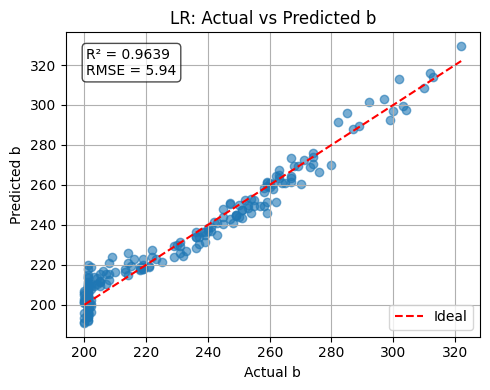

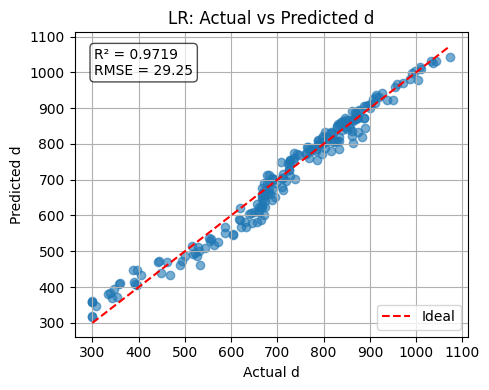

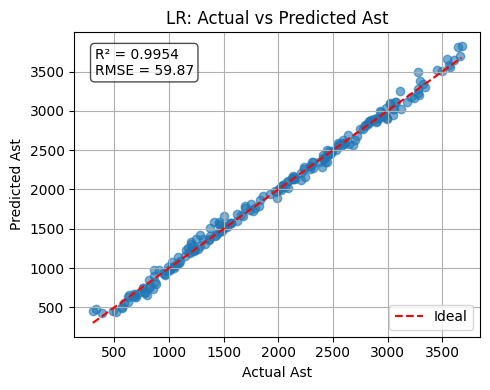

In [ ]:
plot_predictions(y_test, y_pred)

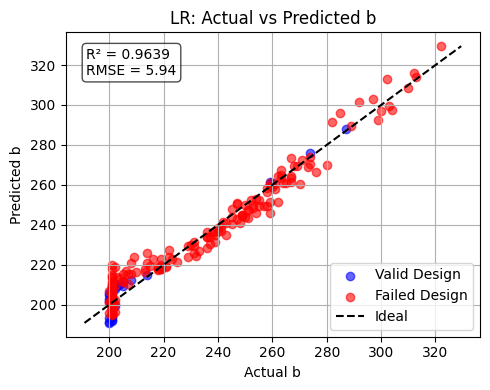

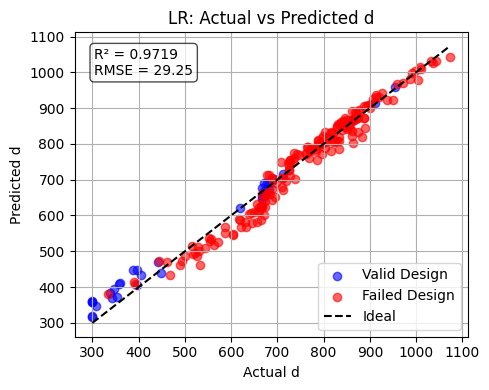

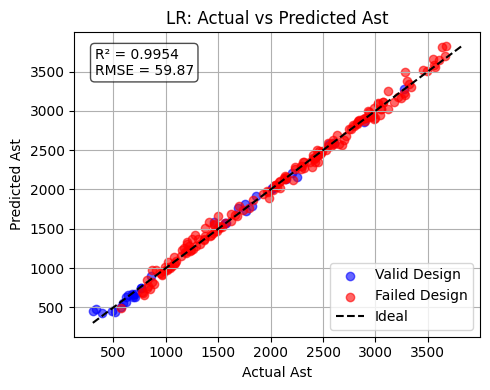

In [ ]:
plot_predictions_validity(y_test, y_pred, X_test)

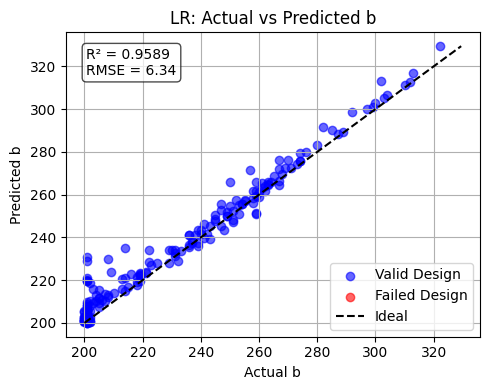

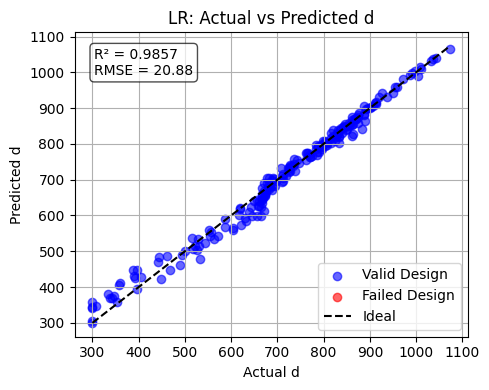

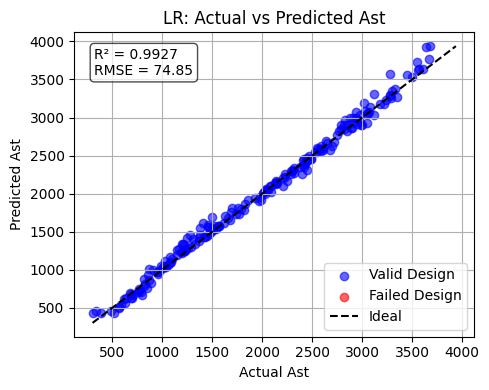

In [ ]:
plot_predictions_validity(y_test, y_pred_safe, X_test)

In [ ]:
show_random_designs(y_test, y_pred, get_cost, n=5, random_seed=41)

,b_actual,d_actual,Ast_actual,b_pred,d_pred,Ast_pred,Cost_actual,Cost_pred,Cost_accuracy
0,267.0,887.0,1965.7,261.49,906.02,1984.58,5712.74,5734.83,99.61
1,239.0,796.0,3023.5,231.46,802.02,3088.38,6176.49,6178.66,99.96
2,221.0,734.0,2527.8,219.24,752.69,2496.93,5211.26,5219.38,99.84
3,233.0,776.0,2981.9,226.95,789.85,3034.27,5989.23,6023.55,99.43
4,201.0,396.0,515.1,208.05,449.04,437.51,1760.03,1882.19,93.06


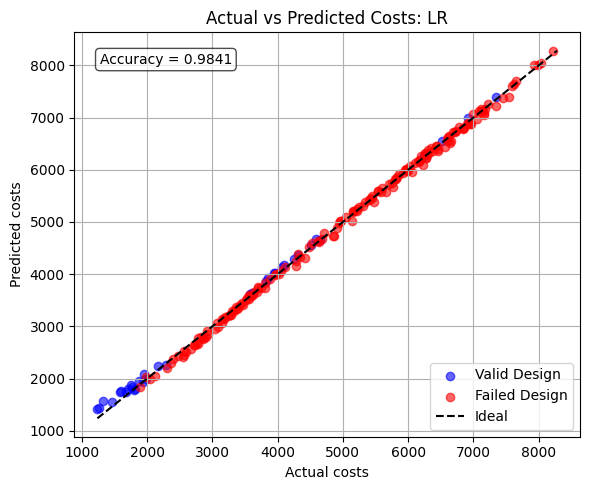

In [ ]:
plot_costs_validity(y_test, y_pred, X_test)

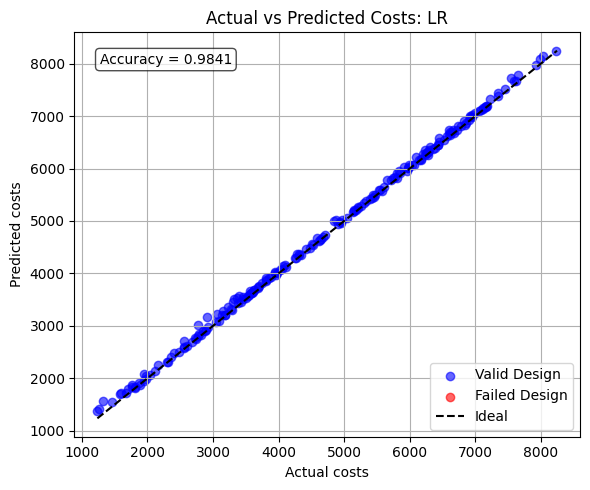

In [ ]:
plot_costs_validity(y_test, y_pred_safe, X_test)

##Random forest regressor

In [ ]:

# Define pipeline
rf_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('regressor', MultiOutputRegressor(
        TransformedTargetRegressor(
            regressor=RandomForestRegressor(n_estimators=100, random_state=42),
            transformer=StandardScaler()
        )
    ))
])

rf_pipeline.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('regressor',
                 MultiOutputRegressor(estimator=TransformedTargetRegressor(regressor=RandomForestRegressor(random_state=42),
                                                                           transformer=StandardScaler())))])

In [ ]:
# Predict
# Predict
y_pred = rf_pipeline.predict(X_test)
y_pred_safe = correct_invalid_predictions(y_pred, X_test)
evaluate_model(y_test, y_pred)


b: R² = 0.9952, RMSE = 2.16
d: R² = 0.9957, RMSE = 11.44
Ast: R² = 0.9971, RMSE = 47.03
Cost accuracy: 0.992


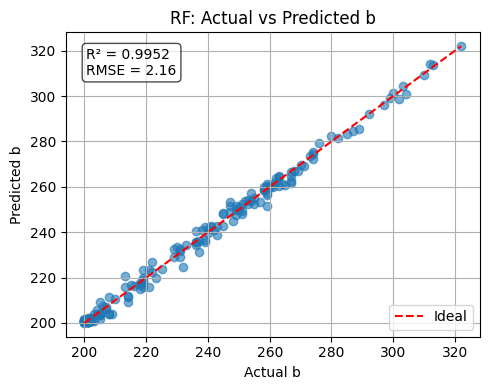

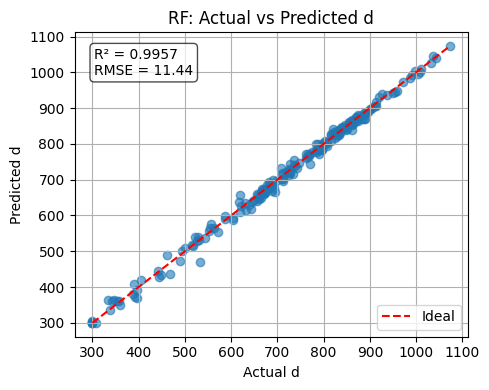

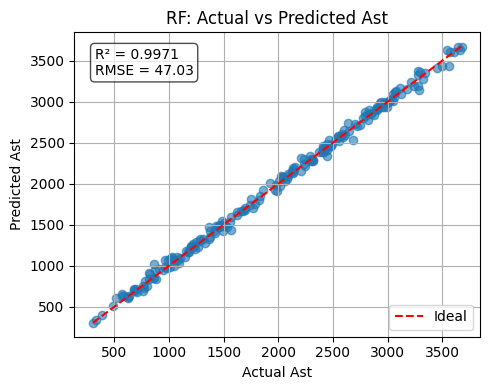

In [ ]:
plot_predictions(y_test, y_pred, model="RF")

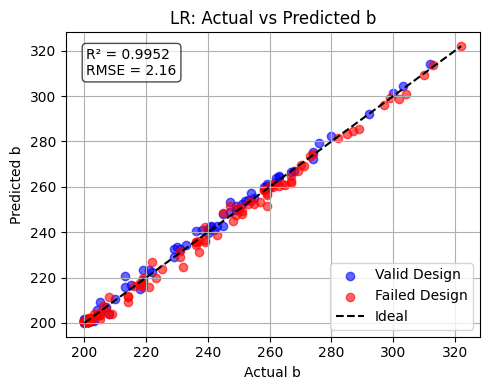

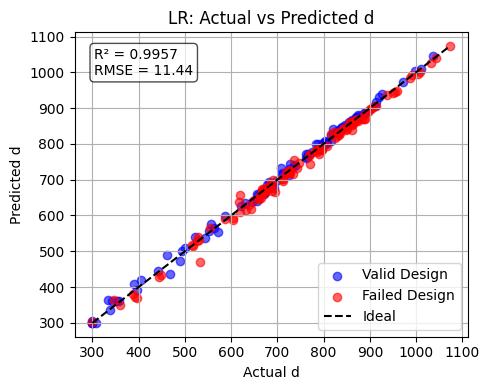

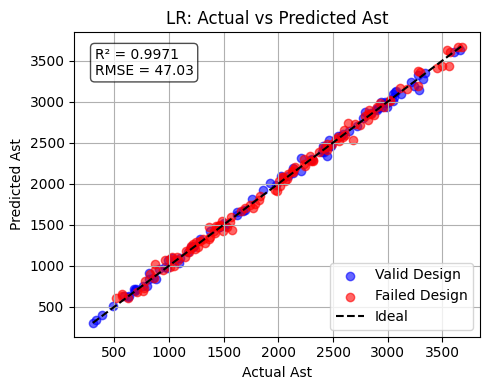

In [ ]:
plot_predictions_validity(y_test, y_pred, X_test)

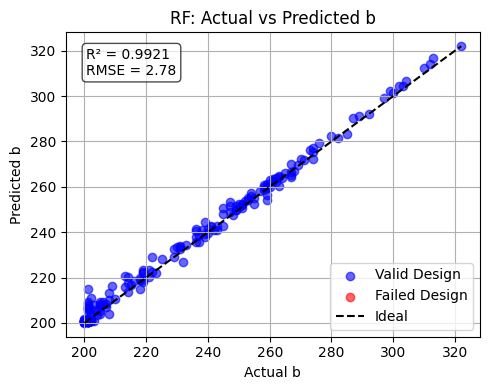

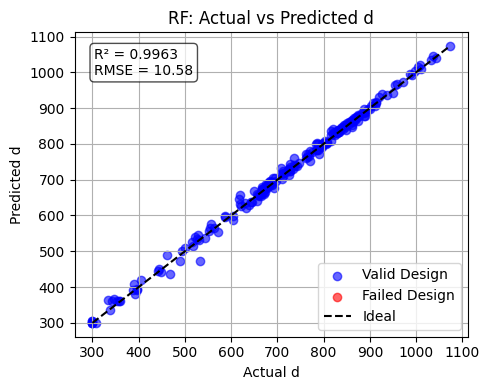

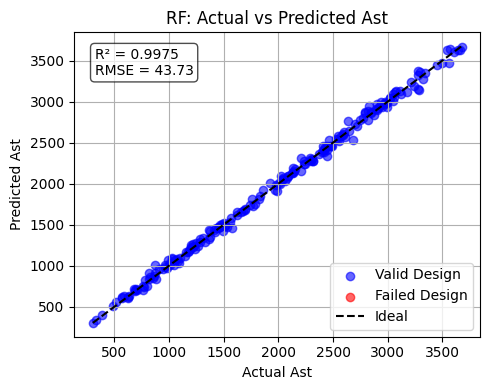

In [ ]:
plot_predictions_validity(y_test, y_pred_safe, X_test, model="RF")

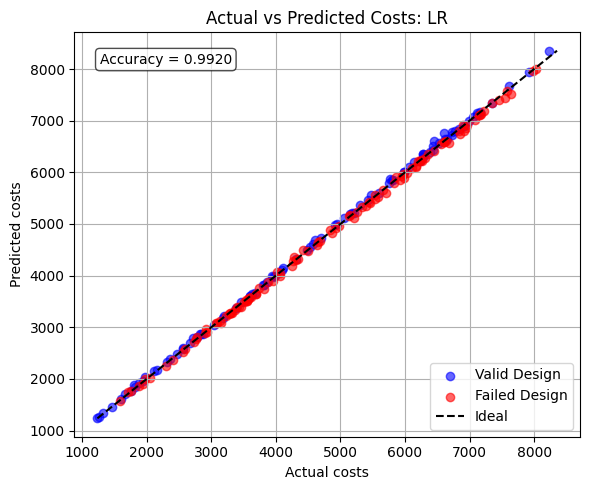

In [ ]:
plot_costs_validity(y_test, y_pred, X_test)

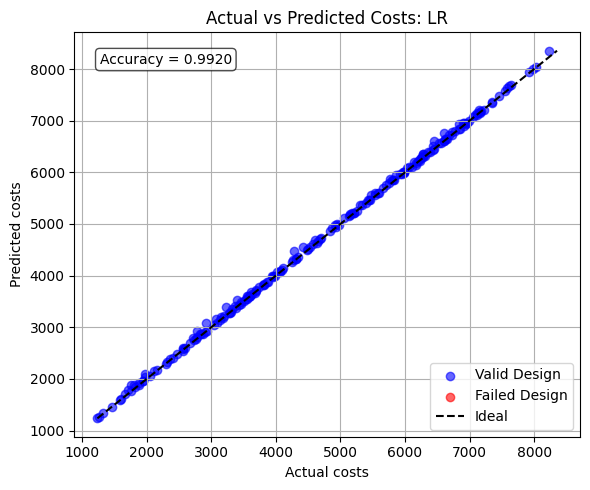

In [ ]:
plot_costs_validity(y_test, y_pred_safe, X_test)

In [ ]:
show_random_designs(y_test, y_pred, get_cost, n=5, random_seed=42)

,b_actual,d_actual,Ast_actual,b_pred,d_pred,Ast_pred,Cost_actual,Cost_pred,Cost_accuracy
0,213.0,710.0,1674.7,215.86,716.46,1669.41,4108.95,4154.50,98.89
1,201.0,346.0,759.7,200.94,364.26,691.70,1878.10,1858.10,98.93
2,218.0,725.0,1924.0,214.88,712.50,2007.85,4485.23,4503.15,99.60
3,236.0,784.0,2989.7,240.31,798.61,2930.12,6061.04,6098.91,99.38
4,213.0,708.0,2448.8,220.48,733.56,2337.53,4953.29,4994.98,99.16


##Gradient boosting regressor

In [ ]:
# Define Gradient Boosting pipeline
gb_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('regressor', MultiOutputRegressor(
        TransformedTargetRegressor(
            regressor=GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42),
            transformer=StandardScaler()
        )
    ))
])
gb_pipeline.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('regressor',
                 MultiOutputRegressor(estimator=TransformedTargetRegressor(regressor=GradientBoostingRegressor(random_state=42),
                                                                           transformer=StandardScaler())))])

In [ ]:
# Predict
y_pred = gb_pipeline.predict(X_test)
y_pred_safe = correct_invalid_predictions(y_pred, X_test)
evaluate_model(y_test, y_pred)

b: R² = 0.9938, RMSE = 2.47
d: R² = 0.9964, RMSE = 10.44
Ast: R² = 0.9977, RMSE = 42.28
Cost accuracy: 0.9933


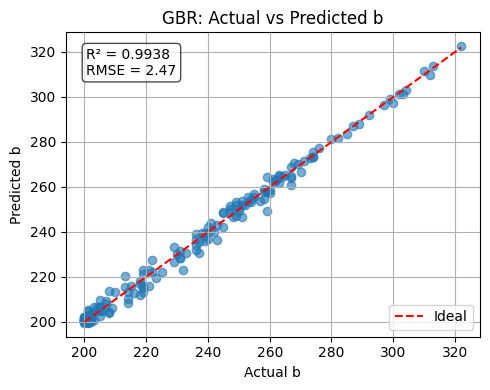

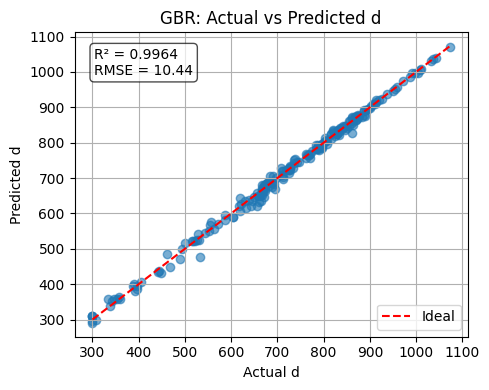

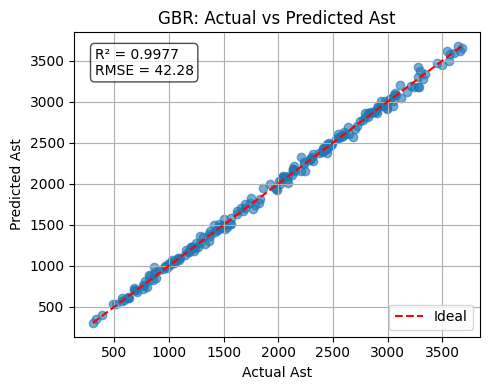

In [ ]:
plot_predictions(y_test, y_pred, model="GBR")

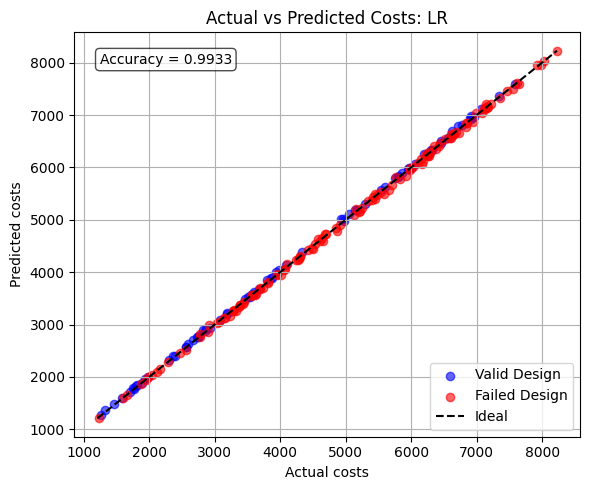

In [ ]:
plot_costs_validity(y_test, y_pred, X_test)

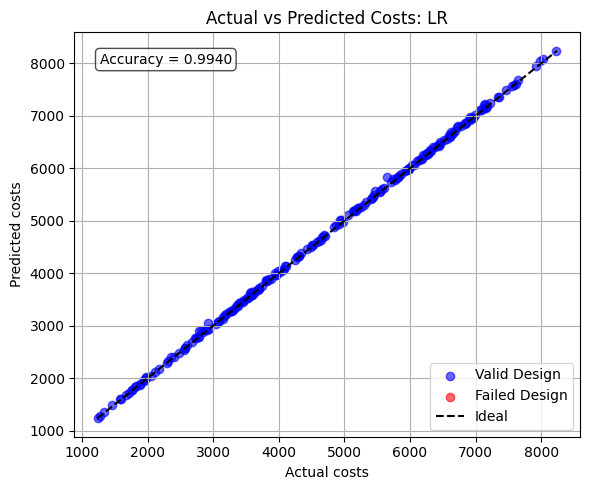

In [ ]:
plot_costs_validity(y_test, y_pred_safe, X_test)

In [ ]:
show_random_designs(y_test, y_pred, get_cost, n=5, random_seed=41)

,b_actual,d_actual,Ast_actual,b_pred,d_pred,Ast_pred,Cost_actual,Cost_pred,Cost_accuracy
0,267.0,887.0,1965.7,263.85,889.80,1948.22,5712.74,5662.72,99.12
1,239.0,796.0,3023.5,235.81,788.94,3030.15,6176.49,6120.79,99.10
2,221.0,734.0,2527.8,215.84,727.77,2541.52,5211.26,5149.34,98.81
3,233.0,776.0,2981.9,230.74,777.68,2973.60,5989.23,5959.68,99.51
4,201.0,396.0,515.1,202.77,395.08,528.63,1760.03,1782.62,98.72


##KNN

In [ ]:
knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsRegressor(n_neighbors=10))
])
knn_reg = TransformedTargetRegressor(
    regressor=knn_pipeline,
    transformer=StandardScaler()
)
param_grid = {
    'regressor__knn__n_neighbors': [3, 5, 10, 15],
    'regressor__knn__weights': ['uniform', 'distance'],
    'regressor__knn__p': [1, 2],  # Manhattan vs Euclidean
}

grid = GridSearchCV(knn_reg, param_grid, cv=5, scoring='neg_mean_squared_error')

grid.fit(X_train, y_train)
best_knn = grid.best_estimator_


In [ ]:
# Predict
y_pred = best_knn.predict(X_test)
y_pred_safe = correct_invalid_predictions(y_pred, X_test)
evaluate_model(y_test, y_pred)

b: R² = 0.9946, RMSE = 2.29
d: R² = 0.9897, RMSE = 17.67
Ast: R² = 0.9952, RMSE = 61.09
Cost accuracy: 0.9778


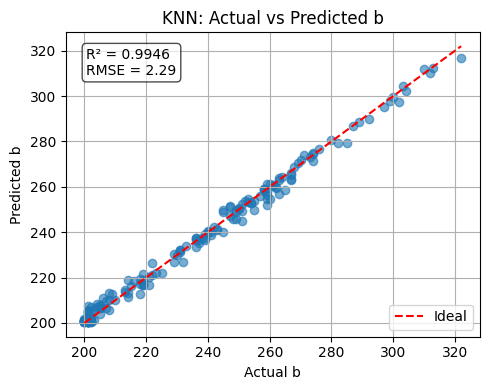

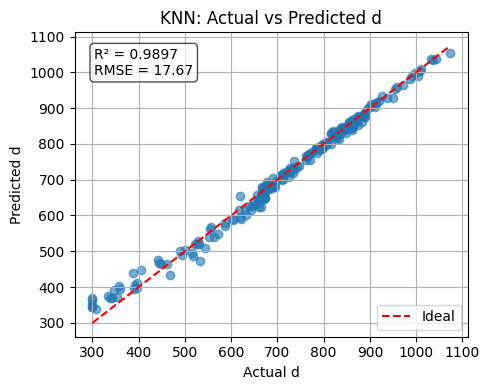

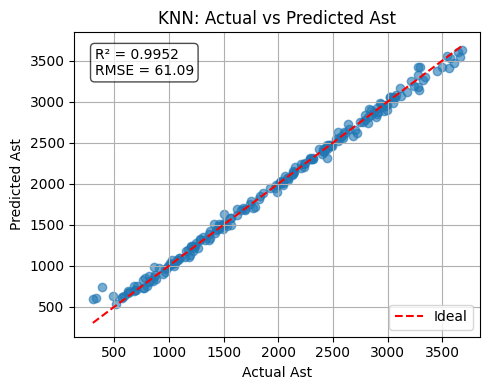

In [ ]:
plot_predictions(y_test, y_pred, model = "KNN")

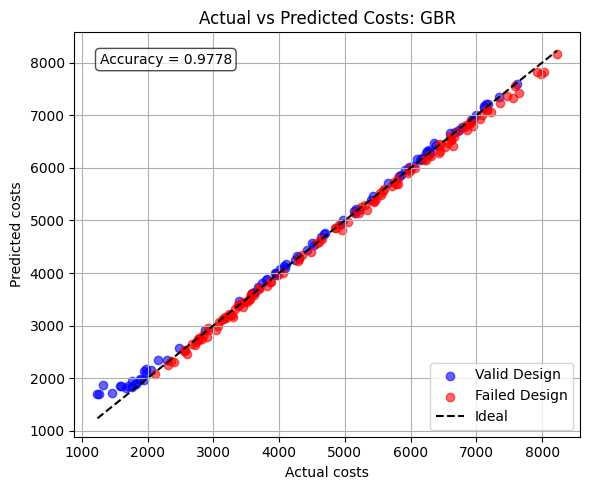

In [ ]:
plot_costs_validity(y_test, y_pred, X_test, model = "GBR")

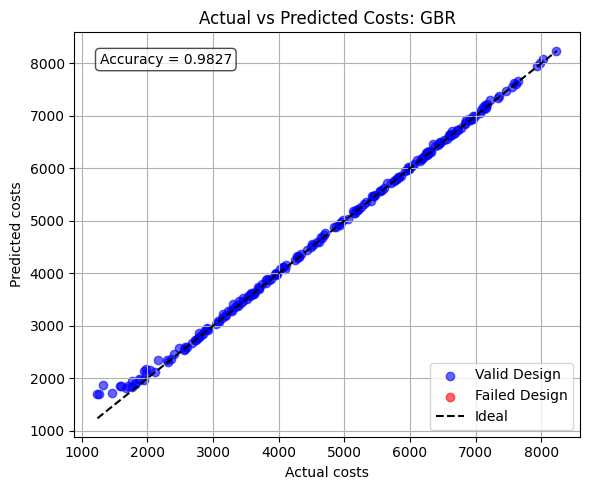

In [ ]:
plot_costs_validity(y_test, y_pred_safe, X_test, model = "GBR")

In [ ]:
show_random_designs(y_test, y_pred, get_cost, n=5, random_seed=42)

,b_actual,d_actual,Ast_actual,b_pred,d_pred,Ast_pred,Cost_actual,Cost_pred,Cost_accuracy
0,213.0,710.0,1674.7,214.63,712.92,1702.27,4108.95,4166.05,98.61
1,201.0,346.0,759.7,200.56,393.25,731.13,1878.10,1986.59,94.22
2,218.0,725.0,1924.0,212.76,707.20,1951.67,4485.23,4401.89,98.14
3,236.0,784.0,2989.7,237.45,789.35,2896.60,6061.04,5994.81,98.91
4,213.0,708.0,2448.8,213.82,711.94,2314.04,4953.29,4826.50,97.44


##Support vector machine

In [ ]:
# Base SVR model with a pipeline (for scaling X)
svr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svr', SVR())
])

# Wrap the SVR pipeline with target scaling and multi-output support
svr_reg = MultiOutputRegressor(
    TransformedTargetRegressor(
        regressor=svr_pipeline,
        transformer=StandardScaler()
    )
)

# Hyperparameter grid
param_grid = {
    'estimator__regressor__svr__C': [1, 10, 100],
    'estimator__regressor__svr__gamma': ['scale', 'auto'],
    'estimator__regressor__svr__kernel': ['rbf', 'poly'],
    'estimator__regressor__svr__epsilon': [0.1, 0.2, 0.5]
}

# GridSearchCV
grid = GridSearchCV(
    svr_reg,
    param_grid,
    cv=3,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    verbose=1
)

# Fit
grid.fit(X_train, y_train)

# Best estimator
best_svr = grid.best_estimator_



Fitting 3 folds for each of 36 candidates, totalling 108 fits


In [ ]:
# Predict
y_pred = best_svr.predict(X_test)
y_pred_safe = correct_invalid_predictions(y_pred, X_test)
evaluate_model(y_test, y_pred)

b: R² = 0.9950, RMSE = 2.20
d: R² = 0.9950, RMSE = 12.29
Ast: R² = 0.9958, RMSE = 57.06
Cost accuracy: 0.9914


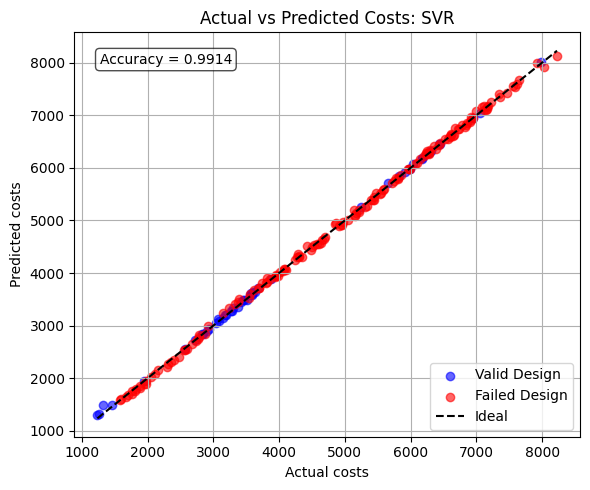

In [ ]:
plot_costs_validity(y_test, y_pred, X_test, model="SVR")

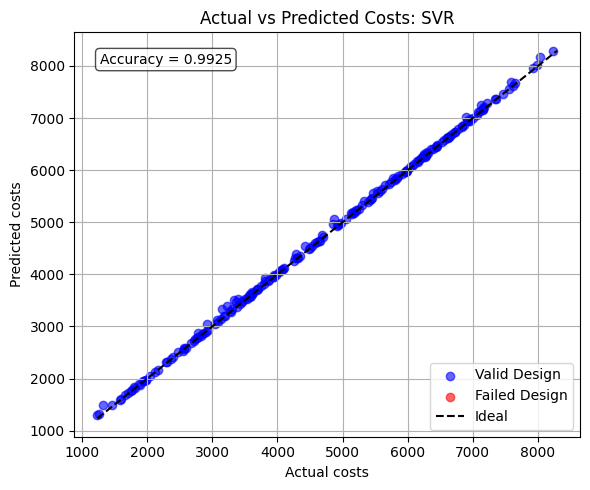

In [ ]:
plot_costs_validity(y_test, y_pred_safe, X_test,  model="SVR")

In [ ]:
show_random_designs(y_test, y_pred, get_cost, n=5, random_seed=42)

,b_actual,d_actual,Ast_actual,b_pred,d_pred,Ast_pred,Cost_actual,Cost_pred,Cost_accuracy
0,213.0,710.0,1674.7,212.55,702.45,1659.48,4108.95,4063.38,98.89
1,201.0,346.0,759.7,201.20,363.79,654.33,1878.10,1817.02,96.75
2,218.0,725.0,1924.0,214.79,714.11,1940.94,4485.23,4433.89,98.86
3,236.0,784.0,2989.7,238.51,803.10,2911.89,6061.04,6073.33,99.80
4,213.0,708.0,2448.8,216.61,709.42,2374.68,4953.29,4914.84,99.22


##XGBoost

In [ ]:
import xgboost as xgb

xgb_model = xgb.XGBRegressor(objective='reg:squarederror', random_state=42)

# Define the parameter grid for GridSearchCV
param_grid_xgb = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 4, 5]
}

# Initialize GridSearchCV
grid_search_xgb = GridSearchCV(xgb_model, param_grid=param_grid_xgb, cv=5, scoring='neg_mean_squared_error')

# Fit GridSearchCV
grid_search_xgb.fit(X_train, y_train)

# Best parameters for XGBoost
best_params_xgb = grid_search_xgb.best_params_
best_xgb = grid_search_xgb.best_estimator_

print(f"Best Parameters for XGBoost: {best_params_xgb}")

Best Parameters for XGBoost: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 300}


In [ ]:
# Predict
y_pred = best_xgb.predict(X_test)
y_pred_safe = correct_invalid_predictions(y_pred, X_test)
evaluate_model(y_test, y_pred)

b: R² = 0.9961, RMSE = 1.95
d: R² = 0.9970, RMSE = 9.60
Ast: R² = 0.9981, RMSE = 38.26
Cost accuracy: 0.9957


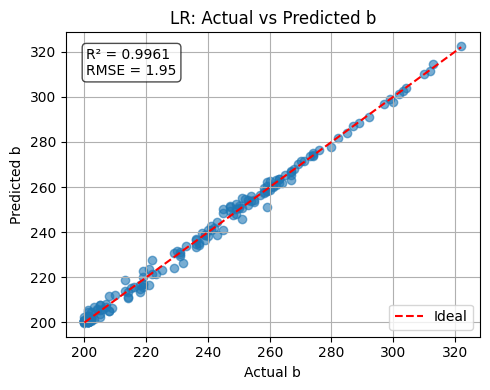

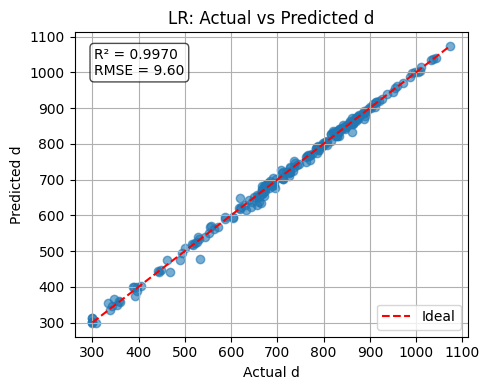

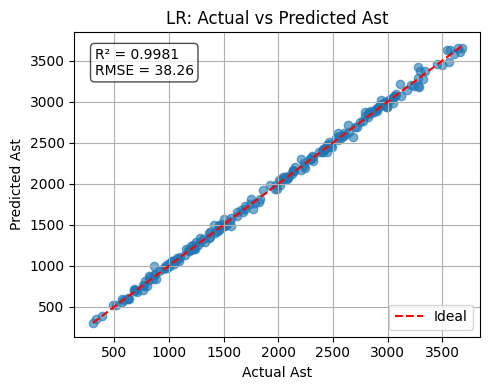

In [ ]:
plot_predictions(y_test, y_pred)

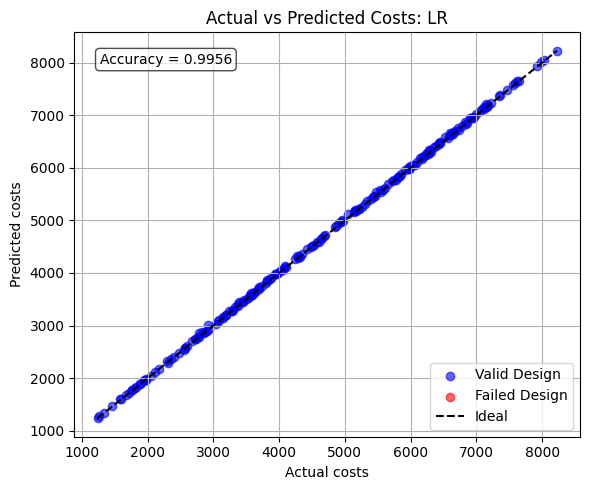

In [ ]:
plot_costs_validity(y_test, y_pred_safe, X_test)

##MLP 1

In [ ]:
# Define pipeline
mlp_pipeline = Pipeline([
    ('scaler', StandardScaler()),       #Scale input features
    ('regressor', MultiOutputRegressor(       #Handle multiple outputs
        TransformedTargetRegressor(           #Scale each target internally
            regressor=MLPRegressor(hidden_layer_sizes=(16, 16),     #MLPRegressor is the core model
                                   activation='relu',
                                   solver='adam',
                                   learning_rate_init=0.001,
                                   max_iter=1000,
                                   alpha=1e-4,
                                   early_stopping=True,
                                   validation_fraction=0.1,
                                   n_iter_no_change=20,
                                   random_state=42),
            transformer=StandardScaler()             #Scale each y variable (b, d, Ast)
        )
    ))
])

# Fit the pipeline on the training data
mlp_pipeline.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('regressor',
                 MultiOutputRegressor(estimator=TransformedTargetRegressor(regressor=MLPRegressor(early_stopping=True,
                                                                                                  hidden_layer_sizes=(16,
                                                                                                                      16),
                                                                                                  max_iter=1000,
                                                                                                  n_iter_no_change=20,
                                                                                                  random_state=42),
                                                                           transformer=StandardScaler())))])

In [ ]:
# Predict
y_pred = mlp_pipeline.predict(X_test)
y_pred_safe = correct_invalid_predictions(y_pred, X_test)
evaluate_model(y_test, y_pred)

b: R² = 0.9910, RMSE = 2.96
d: R² = 0.9942, RMSE = 13.34
Ast: R² = 0.9924, RMSE = 76.47
Cost accuracy: 0.9832


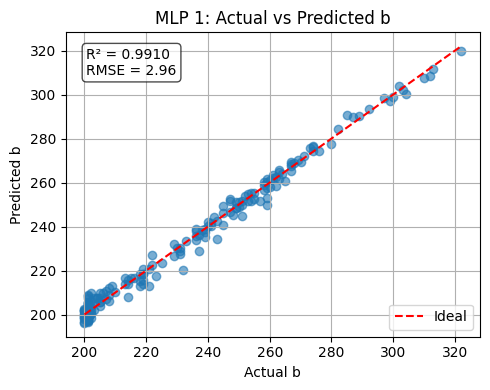

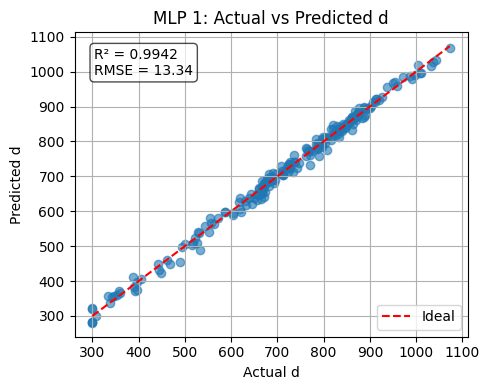

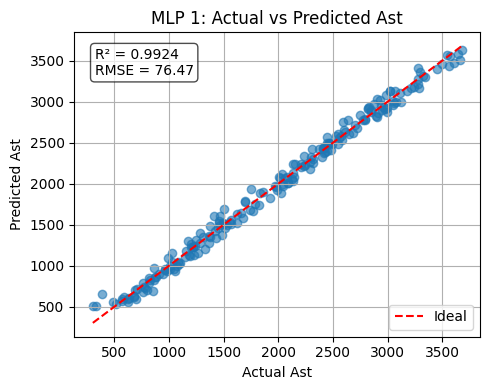

In [ ]:
plot_predictions(y_test, y_pred, model="MLP 1")

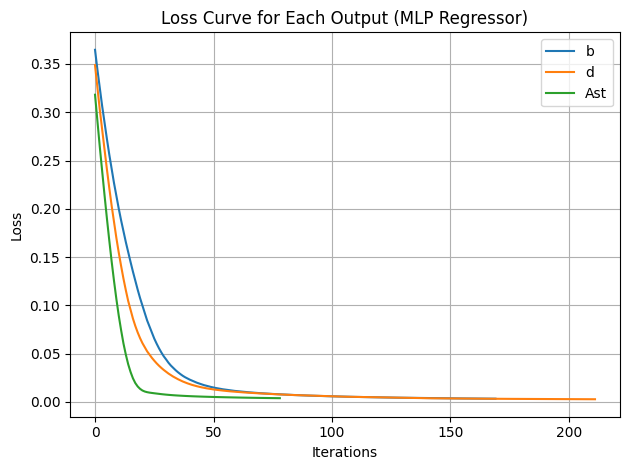

In [ ]:
# Get the internal MLPs from the pipeline
mlp_wrapped = mlp_pipeline.named_steps['regressor']
mlps = [r.regressor_ for r in mlp_wrapped.estimators_]

# Plot loss curve for each
for i, name in enumerate(['b', 'd', 'Ast']):
    loss_curve = mlps[i].loss_curve_
    plt.plot(loss_curve, label=f'{name}')

plt.title("Loss Curve for Each Output (MLP Regressor)")
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


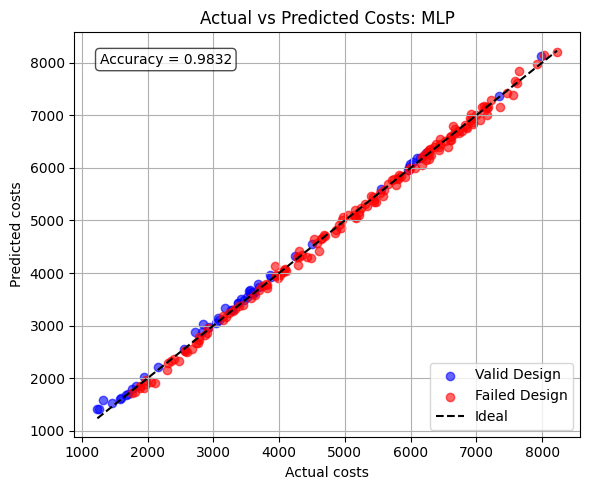

In [ ]:
plot_costs_validity(y_test, y_pred, X_test, model="MLP")

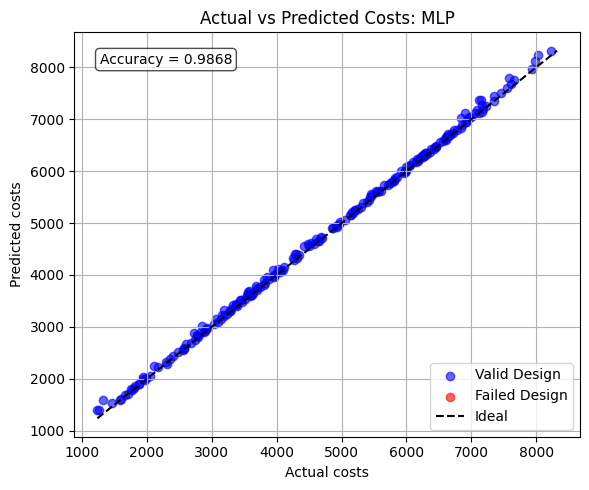

In [ ]:
plot_costs_validity(y_test, y_pred_safe, X_test,  model="MLP")

In [ ]:
show_random_designs(y_test, y_pred, get_cost, n=5, random_seed=42)

,b_actual,d_actual,Ast_actual,b_pred,d_pred,Ast_pred,Cost_actual,Cost_pred,Cost_accuracy
0,213.0,710.0,1674.7,213.92,715.54,1585.95,4108.95,4039.04,98.30
1,201.0,346.0,759.7,196.41,358.59,681.14,1878.10,1805.04,96.11
2,218.0,725.0,1924.0,213.07,714.75,1827.92,4485.23,4293.22,95.72
3,236.0,784.0,2989.7,237.84,793.11,2876.77,6061.04,5991.09,98.85
4,213.0,708.0,2448.8,216.39,728.88,2397.72,4953.29,5000.89,99.04


##PyTorch (MLP 2)


In [ ]:
# Fix random seeds
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
random.seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

# MLP Model
class MultiOutputNN(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 16),
            nn.ReLU(),
            nn.Linear(16, 16),
            nn.ReLU(),
            nn.Linear(16, output_dim)
        )

    def forward(self, x):
        return self.net(x)

# Sklearn-style Wrapper
class TorchRegressor:
    def __init__(self, input_dim, output_dim, lr=0.001, weight_decay=1e-4, epochs=500, batch_size=32, device=None):
        self.input_dim = input_dim
        self.output_dim = output_dim
        self.lr = lr
        self.weight_decay = weight_decay
        self.epochs = epochs
        self.batch_size = batch_size
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")

        self.model = MultiOutputNN(input_dim, output_dim).to(self.device)
        self.criterion = nn.MSELoss()
        self.optimizer = optim.Adam(self.model.parameters(), lr=lr, weight_decay=weight_decay)

        # scalers
        self.scaler_X = StandardScaler()
        self.scaler_y = StandardScaler()

        # history
        self.train_losses = []
        self.val_losses = []

    def fit(self, X, y, X_val=None, y_val=None):
        # scale
        X_scaled = self.scaler_X.fit_transform(X)
        y_scaled = self.scaler_y.fit_transform(y)

        # convert to tensors
        X_tensor = torch.tensor(X_scaled, dtype=torch.float32)
        y_tensor = torch.tensor(y_scaled, dtype=torch.float32)
        dataset = TensorDataset(X_tensor, y_tensor)
        loader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

        if X_val is not None and y_val is not None:
            X_val_scaled = self.scaler_X.transform(X_val)
            y_val_scaled = self.scaler_y.transform(y_val)
            X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32).to(self.device)
            y_val_tensor = torch.tensor(y_val_scaled, dtype=torch.float32).to(self.device)

        for epoch in range(self.epochs):
            self.model.train()
            running_loss = 0.0
            for X_batch, y_batch in loader:
                X_batch, y_batch = X_batch.to(self.device), y_batch.to(self.device)
                self.optimizer.zero_grad()
                outputs = self.model(X_batch)
                loss = self.criterion(outputs, y_batch)
                loss.backward()
                self.optimizer.step()
                running_loss += loss.item() * X_batch.size(0)

            epoch_loss = running_loss / len(loader.dataset)
            self.train_losses.append(epoch_loss)

            if X_val is not None and y_val is not None:
                self.model.eval()
                with torch.no_grad():
                    val_outputs = self.model(X_val_tensor)
                    val_loss = self.criterion(val_outputs, y_val_tensor).item()
                self.val_losses.append(val_loss)

                if (epoch + 1) % 50 == 0:
                    print(f"Epoch {epoch+1}/{self.epochs}, Train Loss: {epoch_loss:.4f}, Val Loss: {val_loss:.4f}")

    def predict(self, X):
        self.model.eval()
        X_scaled = self.scaler_X.transform(X)
        X_tensor = torch.tensor(X_scaled, dtype=torch.float32).to(self.device)
        with torch.no_grad():
            y_pred_scaled = self.model(X_tensor).cpu().numpy()
        return self.scaler_y.inverse_transform(y_pred_scaled)

Epoch 50/500, Train Loss: 0.0077, Val Loss: 0.0077
Epoch 100/500, Train Loss: 0.0041, Val Loss: 0.0041
Epoch 150/500, Train Loss: 0.0032, Val Loss: 0.0035
Epoch 200/500, Train Loss: 0.0029, Val Loss: 0.0032
Epoch 250/500, Train Loss: 0.0027, Val Loss: 0.0033
Epoch 300/500, Train Loss: 0.0026, Val Loss: 0.0032
Epoch 350/500, Train Loss: 0.0026, Val Loss: 0.0031
Epoch 400/500, Train Loss: 0.0025, Val Loss: 0.0029
Epoch 450/500, Train Loss: 0.0025, Val Loss: 0.0031
Epoch 500/500, Train Loss: 0.0025, Val Loss: 0.0028


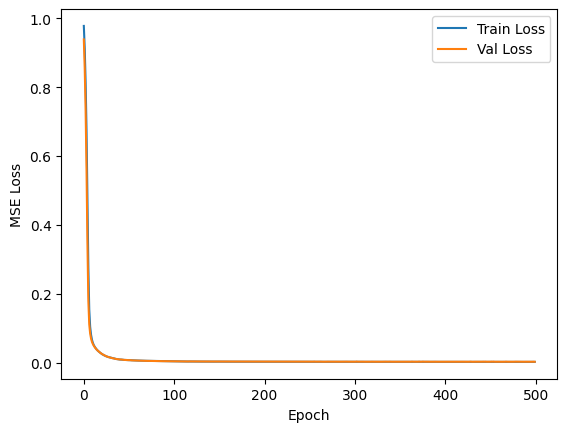

In [ ]:
# Fit
reg = TorchRegressor(input_dim=3, output_dim=3, epochs=500)
reg.fit(X_train, y_train, X_val=X_test, y_val=y_test)

# Plot losses
plt.plot(reg.train_losses, label="Train Loss")
plt.plot(reg.val_losses, label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.show()

In [ ]:
import joblib
reg = joblib.load('torch_reg.pkl')

In [ ]:
# Predict (like sklearn!)
y_pred = reg.predict(X_test)
evaluate_model(y_test, y_pred)

b: R² = 0.9972, RMSE = 1.65
d: R² = 0.9969, RMSE = 9.69
Ast: R² = 0.9974, RMSE = 45.12
Cost accuracy: 0.9929


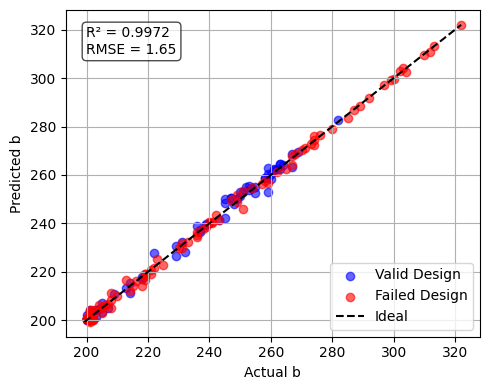

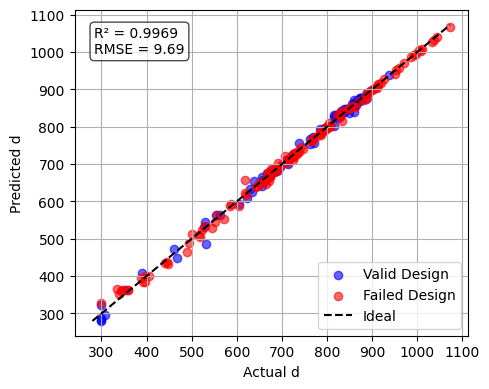

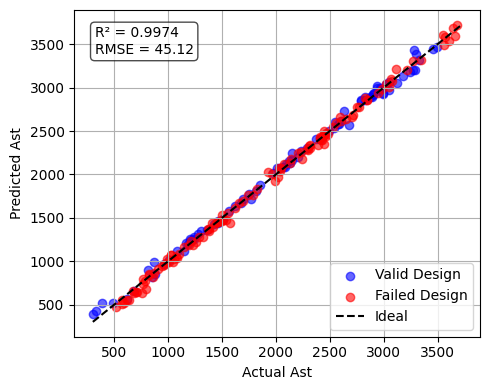

In [ ]:
plot_predictions_validity(y_test, y_pred, X_test, saveas="uncorrected")

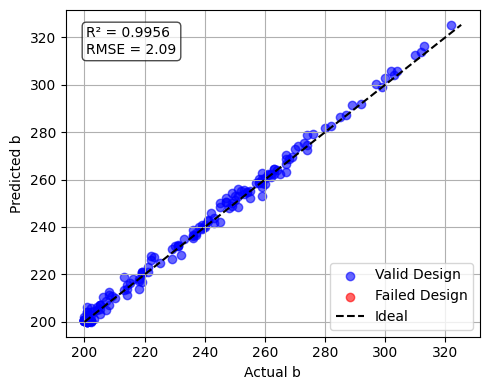

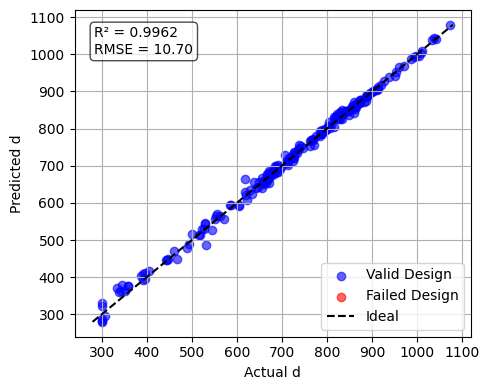

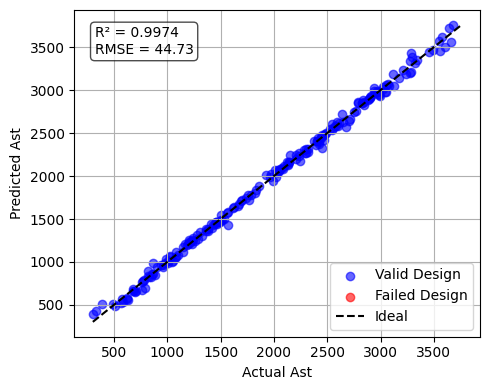

In [ ]:
y_pred_safe = correct_invalid_predictions(y_pred, X_test)
plot_predictions_validity(y_test, y_pred_safe, X_test, saveas="corrected")

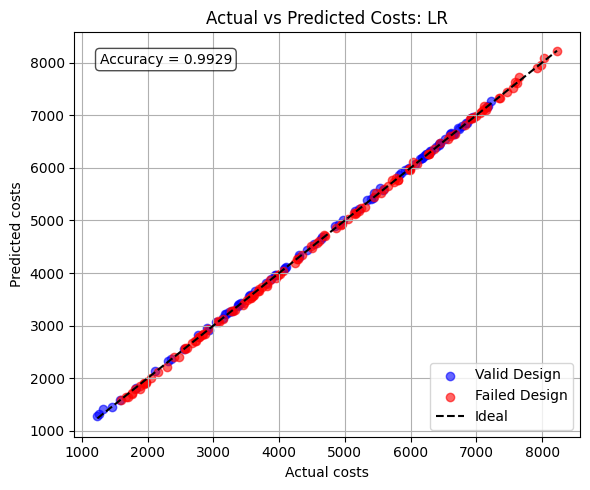

In [ ]:
plot_costs_validity(y_test, y_pred, X_test)

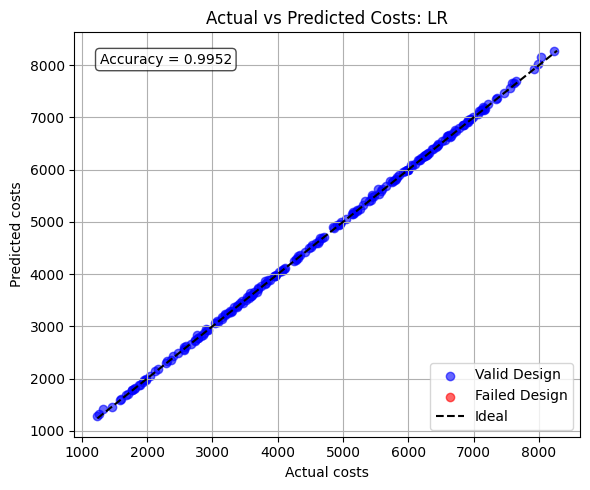

In [ ]:
plot_costs_validity(y_test, y_pred_safe, X_test)

In [ ]:
# Identify indices where the original prediction was invalid
failed_indices = [
    i for i in range(len(y_pred))
    if not is_valid_design(*y_pred[i], *X_test[i])
]

# Randomly sample 5 failed cases (or fewer if less than 5 failed)
n_samples = min(5, len(failed_indices))
np.random.seed(1)
sample_indices = np.random.choice(failed_indices, size=n_samples, replace=False)

records = []
for idx in sample_indices:
    fck, fy, Mu = X_test[idx]
    b_orig, d_orig, Ast_orig = y_pred[idx]
    b_corr, d_corr, Ast_corr = y_pred_safe[idx]

    records.append({
        'fck': fck,
        'fy': fy,
        'Mu': Mu,
        'b_orig': round(b_orig, 2),
        'd_orig': round(d_orig, 2),
        'Ast_orig': round(Ast_orig, 2),
        'Cost_orig': round(get_cost(b_orig, d_orig, Ast_orig), 2),
        'Valid_Before': is_valid_design(b_orig, d_orig, Ast_orig, fck, fy, Mu),
        'b_corr': round(b_corr, 2),
        'd_corr': round(d_corr, 2),
        'Ast_corr': round(Ast_corr, 2),
        'Cost_corr': round(get_cost(b_corr, d_corr, Ast_corr), 2),
        'Valid_After': is_valid_design(b_corr, d_corr, Ast_corr, fck, fy, Mu),
        'Cost_diff_%': round(((get_cost(b_corr, d_corr, Ast_corr) - get_cost(b_orig, d_orig, Ast_orig)) / get_cost(b_orig, d_orig, Ast_orig)) * 100, 2),


    })

df_failed_corrected = pd.DataFrame(records)
df_failed_corrected

,fck,fy,Mu,b_orig,d_orig,Ast_orig,Cost_orig,Valid_Before,b_corr,d_corr,Ast_corr,Cost_corr,Valid_After,Cost_diff_%
0,50,415,740,234.380005,779.260010,3041.679932,6082.490234,False,236.73,787.05,3011.26,6104.13,True,0.36
1,30,415,540,229.860001,762.780029,2397.030029,5264.310059,False,232.16,770.40,2397.03,5317.17,True,1.00
2,30,550,380,206.860001,687.460022,1392.550049,3663.500000,False,208.93,694.33,1392.55,3706.37,True,1.17
3,30,500,200,201.259995,534.210022,995.770020,2707.070068,False,201.26,544.90,995.77,2739.33,True,1.19
4,35,550,420,205.160004,679.640015,1554.130005,3799.520020,False,207.21,679.64,1569.67,3837.52,True,1.00


In [ ]:
sample_indices

array([173, 100, 113, 202, 137])

In [ ]:
print(y_pred[173])
print(X_test[173])


[ 234.38293  779.26117 3041.6787 ]
[ 50 415 740]


In [ ]:
is_valid_design(*y_pred[173], *X_test[173], verbose=True)

Design Invalid: Applied moment Mu (740) exceeds moment capacity MOR (736.863).


False

In [ ]:
calculate_moment_capacity(*y_pred[173], 50, 415)

(np.float32(736.863), np.float32(982.795))

In [ ]:
calculate_moment_capacity(*y_pred_safe[173], 50, 415)

(np.float64(740.298), np.float64(1012.567))

### On new dataset B

In [ ]:
df_new = pd.read_csv("new_ensemble_best_designs.csv")
X_test_new = df_new[['fck','fy','Mu']].values
y_test_new = df_new[['b','d','Ast']].values
y_pred_new = reg.predict(X_test_new)
evaluate_model(y_test_new, y_pred_new)

b: R² = 0.8861, RMSE = 3.78
d: R² = 0.9288, RMSE = 9.82
Ast: R² = 0.9266, RMSE = 60.74
Cost accuracy: 0.9877


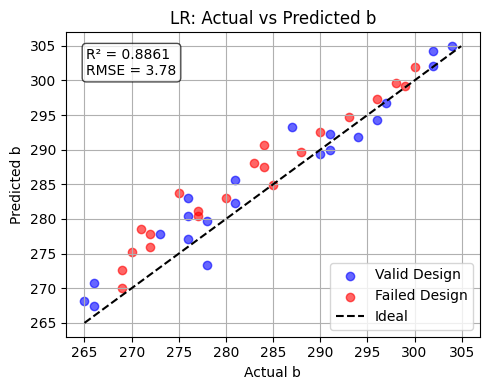

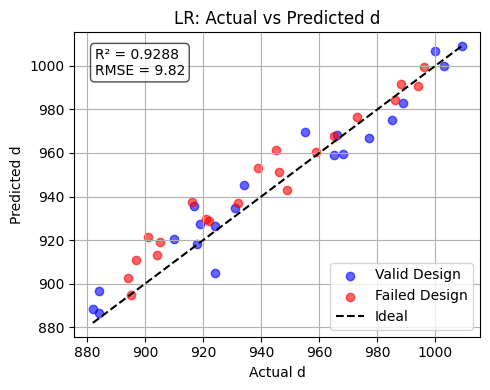

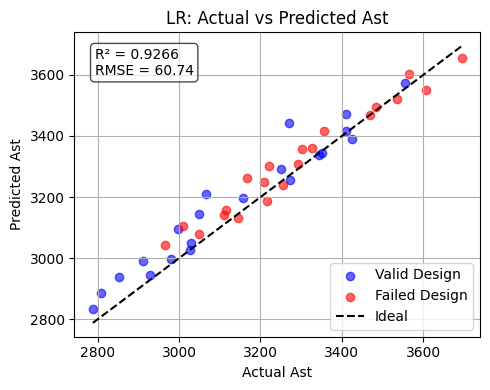

In [ ]:
plot_predictions_validity(y_test_new, y_pred_new, X_test)

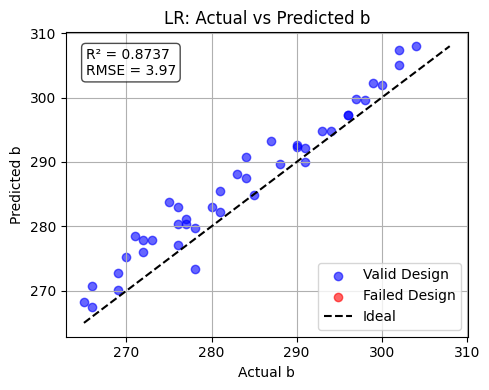

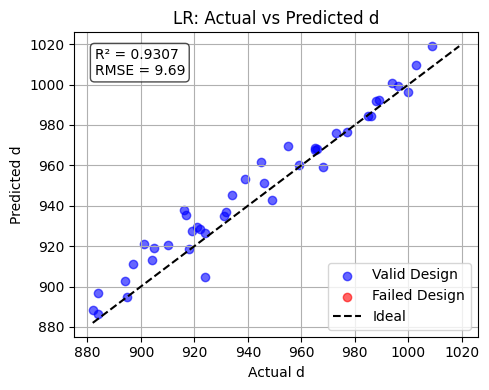

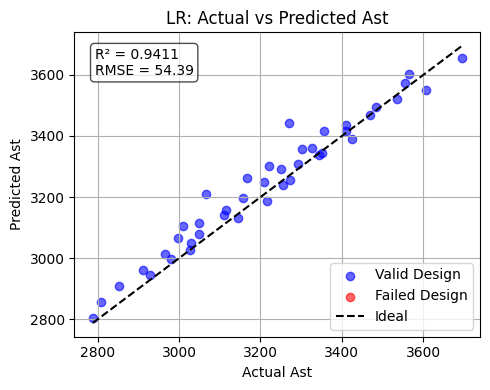

In [ ]:
y_pred__new_safe = correct_invalid_predictions(y_pred_new, X_test_new)
plot_predictions_validity(y_test_new, y_pred__new_safe, X_test_new)

##Summary

In [ ]:
import joblib

joblib.dump(linear_poly, 'linear_poly.pkl')
joblib.dump(rf_pipeline, 'rf_pipeline.pkl')
joblib.dump(gb_pipeline, 'gb_pipeline.pkl')
joblib.dump(best_knn, 'best_knn.pkl')
joblib.dump(best_svr, 'best_svr.pkl')
joblib.dump(mlp_pipeline, 'mlp_pipeline.pkl')
joblib.dump(reg, 'torch_reg.pkl')   #this way of saving torch regressor would require to load the class later for accessing
joblib.dump(best_xgb,'best_xgb.pkl' )

###Importing models

In [ ]:
#this way of saving torch regressor would not require reloading the class
# torch.save(reg.model.state_dict(), "model_state.pt")
# joblib.dump((reg.scaler_X, reg.scaler_y), "scalers.pkl")

#then to load we simply do:
# reg_new = TorchRegressor(input_dim=3, output_dim=3)
# reg_new.model.load_state_dict(torch.load("model_state.pt"))
# reg_new.scaler_X, reg_new.scaler_y = joblib.load("scalers.pkl")

In [ ]:
import joblib
linear_poly = joblib.load('linear_poly.pkl')
rf_pipeline = joblib.load('rf_pipeline.pkl')
gb_pipeline = joblib.load('gb_pipeline.pkl')
best_knn = joblib.load('best_knn.pkl')
best_svr = joblib.load('best_svr.pkl')
mlp_pipeline = joblib.load('mlp_pipeline.pkl')
torch_reg = joblib.load('torch_reg.pkl')
best_xgb = joblib.load('best_xgb.pkl')

/usr/lib/python3.13/pickle.py:1754: UserWarning: [02:52:42] WARNING: /__w/xgboost/xgboost/src/collective/../data/../common/error_msg.h:83: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that version first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

for more details about differences between saving model and serializing.

  setstate(state)


###Seeing parameters

In [ ]:
linear_poly.get_params()

{'memory': None,
 'steps': [('poly', PolynomialFeatures()), ('linear', LinearRegression())],
 'transform_input': None,
 'verbose': False,
 'poly': PolynomialFeatures(),
 'linear': LinearRegression(),
 'poly__degree': 2,
 'poly__include_bias': True,
 'poly__interaction_only': False,
 'poly__order': 'C',
 'linear__copy_X': True,
 'linear__fit_intercept': True,
 'linear__n_jobs': None,
 'linear__positive': False}

In [ ]:
best_svr.get_params()

{'estimator__check_inverse': True,
 'estimator__func': None,
 'estimator__inverse_func': None,
 'estimator__regressor__memory': None,
 'estimator__regressor__steps': [('scaler', StandardScaler()),
  ('svr', SVR(C=100))],
 'estimator__regressor__transform_input': None,
 'estimator__regressor__verbose': False,
 'estimator__regressor__scaler': StandardScaler(),
 'estimator__regressor__svr': SVR(C=100),
 'estimator__regressor__scaler__copy': True,
 'estimator__regressor__scaler__with_mean': True,
 'estimator__regressor__scaler__with_std': True,
 'estimator__regressor__svr__C': 100,
 'estimator__regressor__svr__cache_size': 200,
 'estimator__regressor__svr__coef0': 0.0,
 'estimator__regressor__svr__degree': 3,
 'estimator__regressor__svr__epsilon': 0.1,
 'estimator__regressor__svr__gamma': 'scale',
 'estimator__regressor__svr__kernel': 'rbf',
 'estimator__regressor__svr__max_iter': -1,
 'estimator__regressor__svr__shrinking': True,
 'estimator__regressor__svr__tol': 0.001,
 'estimator__regr

In [ ]:
best_knn.get_params()

{'check_inverse': True,
 'func': None,
 'inverse_func': None,
 'regressor__memory': None,
 'regressor__steps': [('scaler', StandardScaler()),
  ('knn', KNeighborsRegressor(n_neighbors=10, weights='distance'))],
 'regressor__transform_input': None,
 'regressor__verbose': False,
 'regressor__scaler': StandardScaler(),
 'regressor__knn': KNeighborsRegressor(n_neighbors=10, weights='distance'),
 'regressor__scaler__copy': True,
 'regressor__scaler__with_mean': True,
 'regressor__scaler__with_std': True,
 'regressor__knn__algorithm': 'auto',
 'regressor__knn__leaf_size': 30,
 'regressor__knn__metric': 'minkowski',
 'regressor__knn__metric_params': None,
 'regressor__knn__n_jobs': None,
 'regressor__knn__n_neighbors': 10,
 'regressor__knn__p': 2,
 'regressor__knn__weights': 'distance',
 'regressor': Pipeline(steps=[('scaler', StandardScaler()),
                 ('knn',
                  KNeighborsRegressor(n_neighbors=10, weights='distance'))]),
 'transformer__copy': True,
 'transformer__wit

In [ ]:
rf_pipeline.get_params()

{'memory': None,
 'steps': [('scaler', StandardScaler()),
  ('regressor',
   MultiOutputRegressor(estimator=TransformedTargetRegressor(regressor=RandomForestRegressor(random_state=42),
                                                             transformer=StandardScaler())))],
 'transform_input': None,
 'verbose': False,
 'scaler': StandardScaler(),
 'regressor': MultiOutputRegressor(estimator=TransformedTargetRegressor(regressor=RandomForestRegressor(random_state=42),
                                                           transformer=StandardScaler())),
 'scaler__copy': True,
 'scaler__with_mean': True,
 'scaler__with_std': True,
 'regressor__estimator__check_inverse': True,
 'regressor__estimator__func': None,
 'regressor__estimator__inverse_func': None,
 'regressor__estimator__regressor__bootstrap': True,
 'regressor__estimator__regressor__ccp_alpha': 0.0,
 'regressor__estimator__regressor__criterion': 'squared_error',
 'regressor__estimator__regressor__max_depth': None,
 'reg

In [ ]:
gb_pipeline.get_params()

{'memory': None,
 'steps': [('scaler', StandardScaler()),
  ('regressor',
   MultiOutputRegressor(estimator=TransformedTargetRegressor(regressor=GradientBoostingRegressor(random_state=42),
                                                             transformer=StandardScaler())))],
 'transform_input': None,
 'verbose': False,
 'scaler': StandardScaler(),
 'regressor': MultiOutputRegressor(estimator=TransformedTargetRegressor(regressor=GradientBoostingRegressor(random_state=42),
                                                           transformer=StandardScaler())),
 'scaler__copy': True,
 'scaler__with_mean': True,
 'scaler__with_std': True,
 'regressor__estimator__check_inverse': True,
 'regressor__estimator__func': None,
 'regressor__estimator__inverse_func': None,
 'regressor__estimator__regressor__alpha': 0.9,
 'regressor__estimator__regressor__ccp_alpha': 0.0,
 'regressor__estimator__regressor__criterion': 'friedman_mse',
 'regressor__estimator__regressor__init': None,
 'regres

###Evaluation

In [ ]:
models = {'LR': linear_poly, 'KNN': best_knn, 'SVR': best_svr, 'RF': rf_pipeline, 'GB': gb_pipeline, 'XGB': best_xgb, 'MLP 1': mlp_pipeline, 'MLP 2': torch_reg}

In [ ]:
for model_name, model in models.items():
    y_pred = model.predict(X_test)
    print(model_name)
    evaluate_model(y_test, y_pred)
    print('-'*50)


LR
b: R² = 0.9639, RMSE = 5.94
d: R² = 0.9719, RMSE = 29.25
Ast: R² = 0.9954, RMSE = 59.87
Cost accuracy: 0.9841
--------------------------------------------------
KNN
b: R² = 0.9946, RMSE = 2.29
d: R² = 0.9897, RMSE = 17.67
Ast: R² = 0.9952, RMSE = 61.09
Cost accuracy: 0.9778
--------------------------------------------------
SVR
b: R² = 0.9950, RMSE = 2.20
d: R² = 0.9950, RMSE = 12.29
Ast: R² = 0.9958, RMSE = 57.06
Cost accuracy: 0.9914
--------------------------------------------------
RF
b: R² = 0.9952, RMSE = 2.16
d: R² = 0.9957, RMSE = 11.44
Ast: R² = 0.9971, RMSE = 47.03
Cost accuracy: 0.992
--------------------------------------------------
GB
b: R² = 0.9938, RMSE = 2.47
d: R² = 0.9964, RMSE = 10.44
Ast: R² = 0.9977, RMSE = 42.28
Cost accuracy: 0.9933
--------------------------------------------------
XGB
b: R² = 0.9961, RMSE = 1.95
d: R² = 0.9970, RMSE = 9.60
Ast: R² = 0.9981, RMSE = 38.26
Cost accuracy: 0.9957
--------------------------------------------------
MLP 1
b: R² = 0

In [ ]:
scores_list = []

for model_name, model in models.items():
    y_pred = model.predict(X_test)
    b_score = round(r2_score(y_test[:, 0], y_pred[:, 0]),4)
    d_score = round(r2_score(y_test[:, 1], y_pred[:, 1]),4)
    ast_score = round(r2_score(y_test[:, 2], y_pred[:, 2]),4)

    costs_true = [get_cost(b,d,Ast) for b,d,Ast in zip(y_test[:,0], y_test[:,1], y_test[:,2])]
    costs_pred = [get_cost(b,d,Ast) for b,d,Ast in zip(y_pred[:,0], y_pred[:,1], y_pred[:,2])]
    cost_score = get_costs_accuracy(costs_true, costs_pred)

    scores_list.append({
        'Model': model_name,
        'b Score': b_score,
        'd Score': d_score,
        'Ast Score': ast_score,
        'Cost score': cost_score
    })

scores_df = pd.DataFrame(scores_list)
scores_df

,Model,b Score,d Score,Ast Score,Cost score
0,LR,0.9639,0.9719,0.9954,0.9841
1,KNN,0.9946,0.9897,0.9952,0.9778
2,SVR,0.9950,0.9950,0.9958,0.9914
3,RF,0.9952,0.9957,0.9971,0.9920
4,GB,0.9938,0.9964,0.9977,0.9933
5,XGB,0.9961,0.9970,0.9981,0.9957
6,MLP 1,0.9910,0.9942,0.9924,0.9832
7,MLP 2,0.9972,0.9969,0.9974,0.9929


In [ ]:
scores_df.to_csv("scores.csv", index=False)

In [ ]:
scores_df = pd.read_csv("scores.csv")
scores_df.head()

,Model,b Score,d Score,Ast Score,Cost score
0,LR,0.964,0.972,0.995,0.984
1,KNN,0.995,0.990,0.995,0.978
2,SVR,0.995,0.995,0.996,0.991
3,RF,0.995,0.996,0.997,0.992
4,GB,0.994,0.996,0.998,0.993


In [ ]:
scores = scores_df.set_index('Model').drop('Cost score', axis=1)

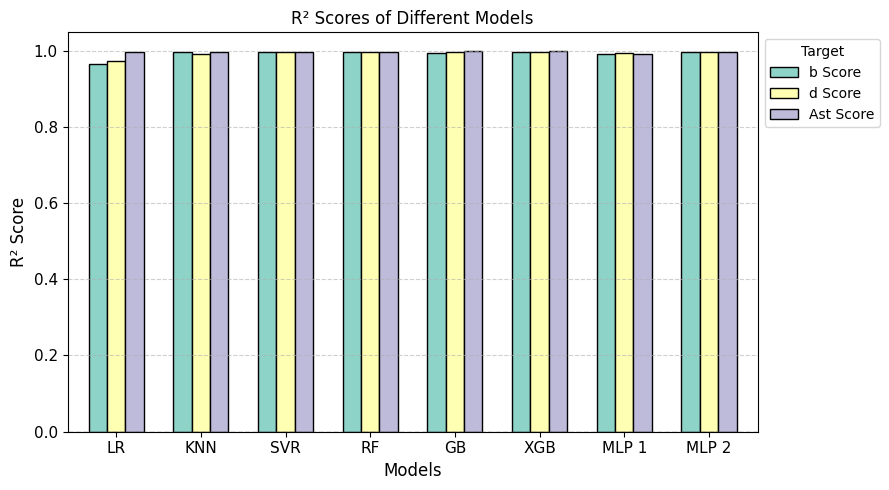

In [ ]:
colors = sns.color_palette("Set3", n_colors=4)

# Plot with improved layout
ax = scores.plot(
    kind='bar',
    figsize=(9, 5),
    width=0.65,                     # narrower bars
    color=colors,
    edgecolor='black',
)

# Improve labels and title
plt.title("R² Scores of Different Models", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.xlabel("Models", fontsize=12)

# Horizontal zero line
plt.axhline(y=0, color='gray', linestyle='--', linewidth=1)

# Axis and grid tweaks
plt.xticks(rotation=0, fontsize=11)
plt.yticks(fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend( fontsize=10, bbox_to_anchor=(1, 1), title="Target")
plt.tight_layout()
plt.show()

#Comparison on new data

In [ ]:
df_new = pd.read_csv("new_ensemble_best_designs.csv")
df_new.describe()

,fck,fy,Mu,b,d,Ast,cost,MOR,Mul,utilization,rho,bd_ratio
count,42.000000,42.000000,42.000000,42.000000,42.000000,42.00000,42.000000,42.000000,42.000000,42.000000,42.000000,42.000000
mean,35.000000,525.000000,1125.000000,283.380952,942.166667,3213.67381,7542.879762,1126.798786,1149.480643,0.998414,0.012124,0.300810
std,4.131969,25.303041,50.606083,11.320071,37.254508,226.88292,332.505601,50.709257,57.404574,0.000795,0.001478,0.000552
min,30.000000,500.000000,1050.000000,265.000000,882.000000,2788.40000,6852.840000,1050.591000,1052.555000,0.995300,0.009800,0.300000
25%,30.000000,500.000000,1075.000000,275.250000,916.250000,3033.82500,7300.007500,1076.798500,1106.302500,0.998100,0.011200,0.300250
50%,35.000000,525.000000,1125.000000,282.000000,936.500000,3218.50000,7539.115000,1126.347500,1151.145000,0.998450,0.012150,0.301000
75%,40.000000,550.000000,1175.000000,292.500000,971.750000,3355.37500,7784.050000,1176.254750,1187.410500,0.999000,0.013175,0.301000
max,40.000000,550.000000,1200.000000,304.000000,1009.000000,3693.90000,8276.490000,1202.439000,1262.945000,0.999500,0.014800,0.302000


In [ ]:
X_test_new = df_new[['fck', 'fy', 'Mu']].values
y_test_new = df_new[['b', 'd', 'Ast']].values

In [ ]:
for model_name, model in models.items():
    y_pred_new = model.predict(X_test_new)
    y_pred_new_safe = correct_invalid_predictions(y_pred_new, X_test_new)
    print(model_name)
    evaluate_model(y_test_new, y_pred_new_safe)
    print('-'*50)


LR
b: R² = -6.6198, RMSE = 30.87
d: R² = 0.2430, RMSE = 32.02
Ast: R² = 0.7308, RMSE = 116.30
Cost accuracy: 0.9523
--------------------------------------------------
KNN
b: R² = 0.5486, RMSE = 7.51
d: R² = 0.5370, RMSE = 25.05
Ast: R² = 0.7269, RMSE = 117.16
Cost accuracy: 0.9886
--------------------------------------------------
SVR
b: R² = -1.9167, RMSE = 19.10
d: R² = 0.6791, RMSE = 20.85
Ast: R² = 0.6241, RMSE = 137.44
Cost accuracy: 0.9767
--------------------------------------------------
RF
b: R² = 0.7198, RMSE = 5.92
d: R² = 0.7204, RMSE = 19.46
Ast: R² = 0.8098, RMSE = 97.76
Cost accuracy: 0.9911
--------------------------------------------------
GB
b: R² = 0.6953, RMSE = 6.17
d: R² = 0.6890, RMSE = 20.53
Ast: R² = 0.8091, RMSE = 97.94
Cost accuracy: 0.9898
--------------------------------------------------
XGB
b: R² = 0.7118, RMSE = 6.00
d: R² = 0.6935, RMSE = 20.38
Ast: R² = 0.8232, RMSE = 94.24
Cost accuracy: 0.9898
--------------------------------------------------
MLP 1


In [ ]:
#evaluation of models on new data
new_scores_list = []

for model_name, model in models.items():
    y_pred_new = model.predict(X_test_new)
    y_pred_new_safe = correct_invalid_predictions(y_pred_new, X_test_new)
    b_score = round(r2_score(y_test_new[:, 0], y_pred_new_safe[:, 0]),4)
    d_score = round(r2_score(y_test_new[:, 1], y_pred_new_safe[:, 1]),4)
    ast_score = round(r2_score(y_test_new[:, 2], y_pred_new_safe[:, 2]),4)

    costs_true = [get_cost(b,d,Ast) for b,d,Ast in zip(y_test_new[:,0], y_test_new[:,1], y_test_new[:,2])]
    costs_pred = [get_cost(b,d,Ast) for b,d,Ast in zip(y_pred_new_safe[:,0], y_pred_new_safe[:,1], y_pred_new_safe[:,2])]
    cost_score = get_costs_accuracy(costs_true, costs_pred)

    new_scores_list.append({
        'Model': model_name,
        'b Score': b_score,
        'd Score': d_score,
        'Ast Score': ast_score,
        'Cost Accuracy': cost_score
    })

new_scores_df = pd.DataFrame(new_scores_list)
new_scores_df


,Model,b Score,d Score,Ast Score,Cost Accuracy
0,LR,-6.6198,0.2430,0.7308,0.9523
1,KNN,0.5486,0.5370,0.7269,0.9886
2,SVR,-1.9167,0.6791,0.6241,0.9767
3,RF,0.7198,0.7204,0.8098,0.9911
4,GB,0.6953,0.6890,0.8091,0.9898
5,XGB,0.7118,0.6935,0.8232,0.9898
6,MLP 1,0.7346,0.8295,0.8143,0.9858
7,MLP 2,0.8737,0.9307,0.9411,0.9866


In [ ]:
new_scores_df.to_csv("new_scores.csv", index=False)

--------------------------------------------------
LR


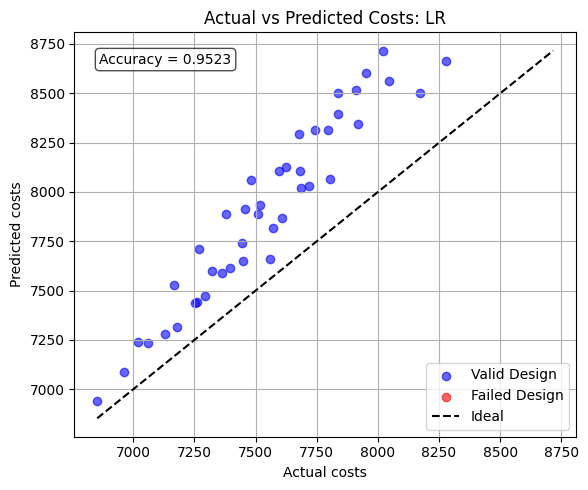

   b_actual  d_actual  Ast_actual  b_pred  d_pred  Ast_pred  Cost_actual  \
0    321.75    912.61     3193.10   284.0   946.0    3116.5      7913.67   
1    355.02    971.06     3121.21   304.0  1009.0    3048.0      8601.42   
2    308.20    962.93     2876.98   294.0   977.0    2807.5      7613.50   
3    329.52    915.55     3257.44   291.0   968.0    3066.8      8105.31   
4    338.47    955.87     3377.13   298.0   988.0    3302.0      8564.50   
5    307.54    870.56     3361.48   272.0   905.0    3255.4      7710.27   
6    330.67    911.00     3636.44   284.0   945.0    3536.2      8515.02   
7    277.44    867.98     3513.55   266.0   884.0    3425.7      7473.55   
8    295.35    863.77     3561.36   278.0   924.0    3269.3      7740.62   
9    332.14    963.34     3517.71   302.0  1000.0    3409.0      8665.42   

   Cost_pred  Cost_accuracy  
0    7454.99          94.20  
1    7950.79          92.44  
2    7394.01          97.12  
3    7595.73          93.71  
4    8045.26 

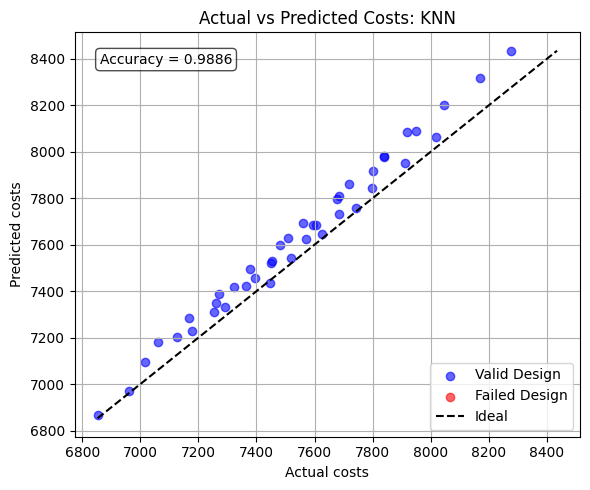

   b_actual  d_actual  Ast_actual  b_pred  d_pred  Ast_pred  Cost_actual  \
0    292.72    973.63     2962.56   284.0   946.0    3116.5      7530.87   
1    312.88   1040.09     2918.36   304.0  1009.0    3048.0      8088.57   
2    297.42    988.52     2773.89   294.0   977.0    2807.5      7458.60   
3    297.11    987.98     2984.78   291.0   968.0    3066.8      7683.39   
4    307.97   1023.98     3159.43   298.0   988.0    3302.0      8202.50   
5    282.20    937.98     3110.47   272.0   905.0    3255.4      7388.89   
6    292.65    972.76     3351.42   284.0   945.0    3536.2      7953.34   
7    272.65    906.52     3297.09   266.0   884.0    3425.7      7330.92   
8    275.27    915.24     3326.91   278.0   924.0    3269.3      7435.41   
9    312.59   1039.51     3239.83   302.0  1000.0    3409.0      8434.75   

   Cost_pred  Cost_accuracy  
0    7454.99          98.99  
1    7950.79          98.30  
2    7394.01          99.13  
3    7595.73          98.86  
4    8045.26 

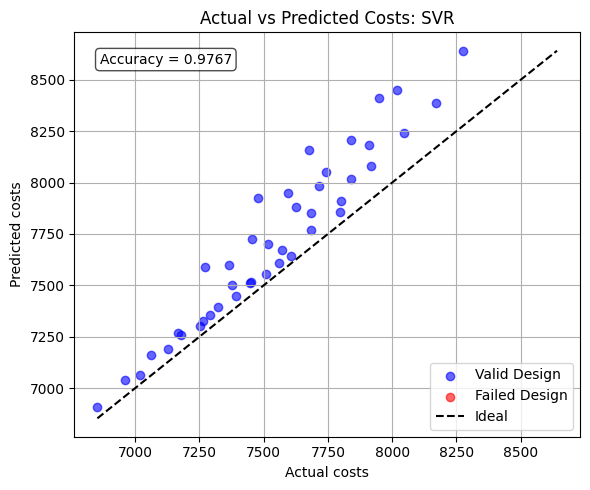

   b_actual  d_actual  Ast_actual  b_pred  d_pred  Ast_pred  Cost_actual  \
0    308.75    947.93     3035.32   284.0   946.0    3116.5      7725.86   
1    336.46   1037.86     2887.85   304.0  1009.0    3048.0      8411.75   
2    295.14    983.03     2818.58   294.0   977.0    2807.5      7449.55   
3    317.85    963.67     3053.80   291.0   968.0    3066.8      7950.66   
4    314.90    998.02     3211.10   298.0   988.0    3302.0      8243.20   
5    300.60    912.93     3160.80   272.0   905.0    3255.4      7590.15   
6    311.57    978.44     3285.46   284.0   945.0    3536.2      8183.49   
7    274.52    899.77     3320.35   266.0   884.0    3425.7      7354.16   
8    279.02    916.35     3344.74   278.0   924.0    3269.3      7511.08   
9    330.18   1036.66     3191.73   302.0  1000.0    3409.0      8641.90   

   Cost_pred  Cost_accuracy  
0    7454.99          96.49  
1    7950.79          94.52  
2    7394.01          99.25  
3    7595.73          95.54  
4    8045.26 

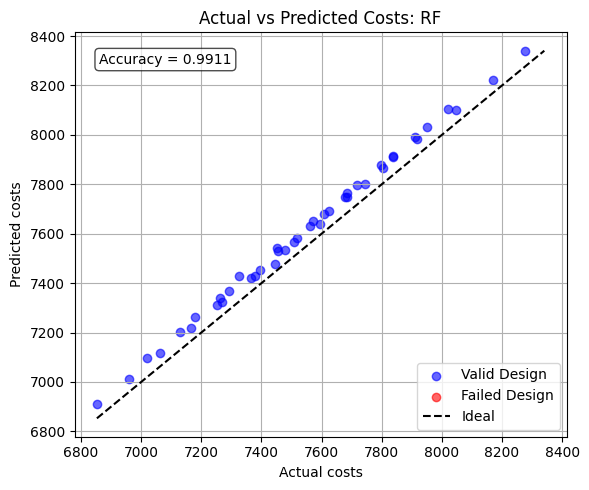

   b_actual  d_actual  Ast_actual  b_pred  d_pred  Ast_pred  Cost_actual  \
0    290.31    964.85     3028.29   284.0   946.0    3116.5      7529.72   
1    310.28   1032.21     2935.96   304.0  1009.0    3048.0      8030.71   
2    296.05    984.86     2801.28   294.0   977.0    2807.5      7452.07   
3    293.03    973.87     3056.59   291.0   968.0    3066.8      7639.72   
4    304.09   1010.76     3176.39   298.0   988.0    3302.0      8101.36   
5    278.67    925.43     3144.45   272.0   905.0    3255.4      7324.11   
6    293.49    975.01     3364.63   284.0   945.0    3536.2      7990.08   
7    272.71    906.77     3331.02   266.0   884.0    3425.7      7370.03   
8    275.33    915.48     3363.05   278.0   924.0    3269.3      7476.91   
9    309.78   1029.66     3235.76   302.0  1000.0    3409.0      8340.58   

   Cost_pred  Cost_accuracy  
0    7454.99          99.01  
1    7950.79          99.00  
2    7394.01          99.22  
3    7595.73          99.42  
4    8045.26 

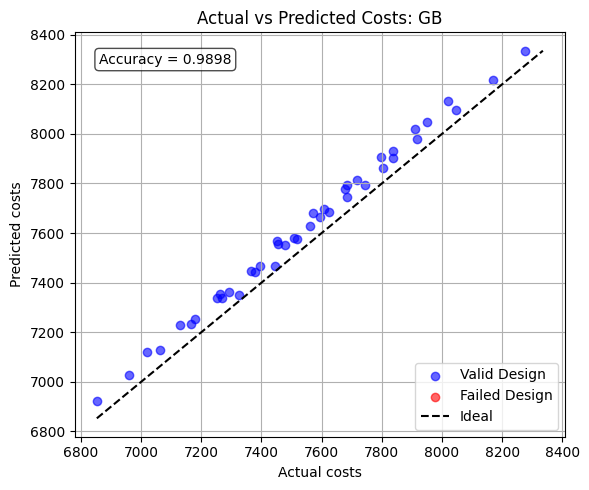

   b_actual  d_actual  Ast_actual  b_pred  d_pred  Ast_pred  Cost_actual  \
0    290.68    967.56     3035.64   284.0   946.0    3116.5      7554.92   
1    310.15   1033.56     2947.25   304.0  1009.0    3048.0      8047.43   
2    295.92    986.15     2812.06   294.0   977.0    2807.5      7467.83   
3    293.40    976.61     3064.01   291.0   968.0    3066.8      7665.32   
4    303.26   1009.23     3190.03   298.0   988.0    3302.0      8096.77   
5    280.08    930.13     3121.91   272.0   905.0    3255.4      7338.71   
6    294.08    975.50     3381.75   284.0   945.0    3536.2      8019.73   
7    273.13    907.99     3312.70   266.0   884.0    3425.7      7360.62   
8    275.75    916.72     3344.56   278.0   924.0    3269.3      7467.51   
9    308.93   1028.09     3249.66   302.0  1000.0    3409.0      8335.53   

   Cost_pred  Cost_accuracy  
0    7454.99          98.68  
1    7950.79          98.80  
2    7394.01          99.01  
3    7595.73          99.09  
4    8045.26 

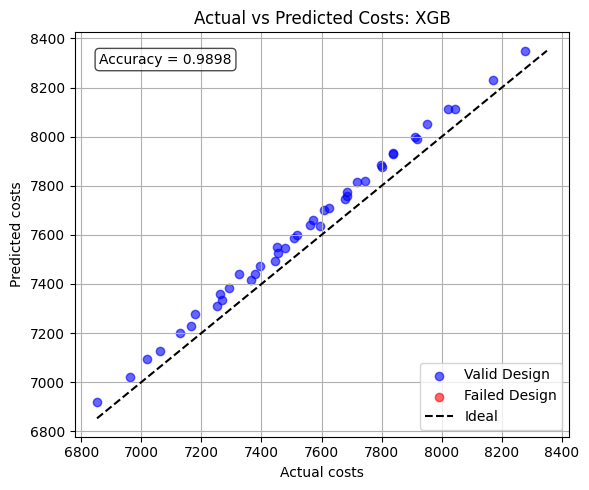

   b_actual  d_actual  Ast_actual  b_pred  d_pred  Ast_pred  Cost_actual  \
0    290.32    965.65     3021.97   284.0   946.0    3116.5      7526.31   
1    310.38   1033.55     2947.52   304.0  1009.0    3048.0      8051.23   
2    296.14    986.14     2812.31   294.0   977.0    2807.5      7471.31   
3    293.03    974.68     3050.21   291.0   968.0    3066.8      7636.32   
4    303.88   1010.70     3187.91   298.0   988.0    3302.0      8110.55   
5    280.16    929.69     3118.46   272.0   905.0    3255.4      7334.14   
6    292.48    973.93     3390.22   284.0   945.0    3536.2      7998.64   
7    273.05    908.21     3334.99   266.0   884.0    3425.7      7384.93   
8    275.67    916.94     3367.05   278.0   924.0    3269.3      7492.05   
9    309.56   1029.59     3247.50   302.0  1000.0    3409.0      8349.87   

   Cost_pred  Cost_accuracy  
0    7454.99          99.05  
1    7950.79          98.75  
2    7394.01          98.97  
3    7595.73          99.47  
4    8045.26 

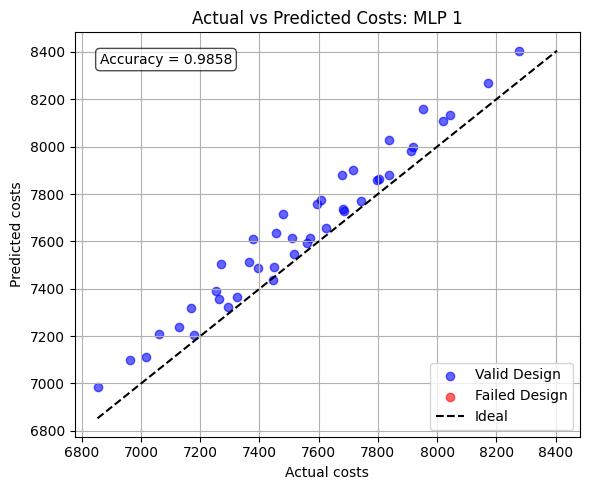

   b_actual  d_actual  Ast_actual  b_pred  d_pred  Ast_pred  Cost_actual  \
0    290.01    953.48     3173.91   284.0   946.0    3116.5      7635.84   
1    308.89   1021.17     3118.62   304.0  1009.0    3048.0      8158.78   
2    298.11    967.47     2877.54   294.0   977.0    2807.5      7488.55   
3    292.78    962.27     3214.81   291.0   968.0    3066.8      7759.04   
4    303.42   1005.04     3237.64   298.0   988.0    3302.0      8132.45   
5    278.13    925.66     3313.79   272.0   905.0    3255.4      7503.73   
6    294.60    970.73     3361.20   284.0   945.0    3536.2      7983.56   
7    273.58    905.40     3281.51   266.0   884.0    3425.7      7321.90   
8    276.42    912.75     3324.43   278.0   924.0    3269.3      7438.05   
9    308.97   1022.44     3336.26   302.0  1000.0    3409.0      8405.10   

   Cost_pred  Cost_accuracy  
0    7454.99          97.63  
1    7950.79          97.45  
2    7394.01          98.74  
3    7595.73          97.90  
4    8045.26 

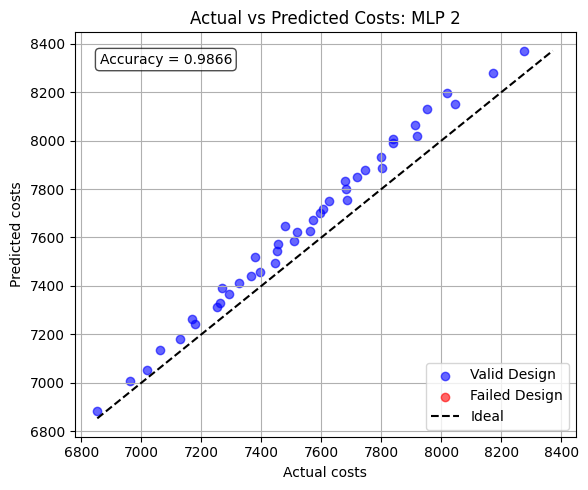

   b_actual  d_actual  Ast_actual  b_pred  d_pred  Ast_pred  Cost_actual  \
0    287.44    951.23     3157.69   284.0   946.0    3116.5      7571.60   
1    307.99   1019.03     3114.75   304.0  1009.0    3048.0      8130.95   
2    294.75    976.72     2857.00   294.0   977.0    2807.5      7458.20   
3    290.02    959.43     3210.85   291.0   968.0    3066.8      7702.58   
4    299.65    991.85     3358.94   298.0   988.0    3302.0      8149.62   
5    277.84    919.22     3239.19   272.0   905.0    3255.4      7390.84   
6    290.73    961.51     3521.27   284.0   945.0    3536.2      8062.96   
7    270.79    896.70     3390.13   266.0   884.0    3425.7      7368.06   
8    273.38    904.90     3443.29   278.0   924.0    3269.3      7494.87   
9    307.32    996.52     3437.05   302.0  1000.0    3409.0      8371.11   

   Cost_pred  Cost_accuracy  
0    7454.99          98.46  
1    7950.79          97.78  
2    7394.01          99.14  
3    7595.73          98.61  
4    8045.26 

In [ ]:
for model_name, model in models.items():
    y_pred_new = model.predict(X_test_new)
    y_pred_new_safe = correct_invalid_predictions(y_pred_new, X_test_new)
    costs_actual = [get_cost(b, d, Ast) for b, d, Ast in zip(y_test_new[:, 0], y_test_new[:, 1], y_test_new[:, 2])]
    costs_pred = [get_cost(b, d, Ast) for b, d, Ast in zip(y_pred_new_safe[:, 0], y_pred_new_safe[:, 1], y_pred_new_safe[:, 2])]
    print('-'*50)
    print(model_name)
    # print_accuracy(costs_actual, costs_pred)

    plot_costs_validity(y_test_new, y_pred_new_safe, X_test_new, model=model_name)
    print(show_random_designs(y_pred_new_safe, y_test_new, get_cost, n=10, random_seed=42))


##More Plots

In [ ]:
new_scores_df = pd.read_csv("new_scores.csv")

In [ ]:
new_scores = new_scores_df.set_index('Model').drop('Cost Accuracy', axis=1)
new_scores

,b Score,d Score,Ast Score
Model,,,
LR,-6.6198,0.2430,0.7308
KNN,0.5486,0.5370,0.7269
SVR,-1.9167,0.6791,0.6241
RF,0.7198,0.7204,0.8098
GB,0.6953,0.6890,0.8091
XGB,0.7118,0.6935,0.8232
MLP 1,0.7346,0.8295,0.8143
MLP 2,0.8737,0.9307,0.9411


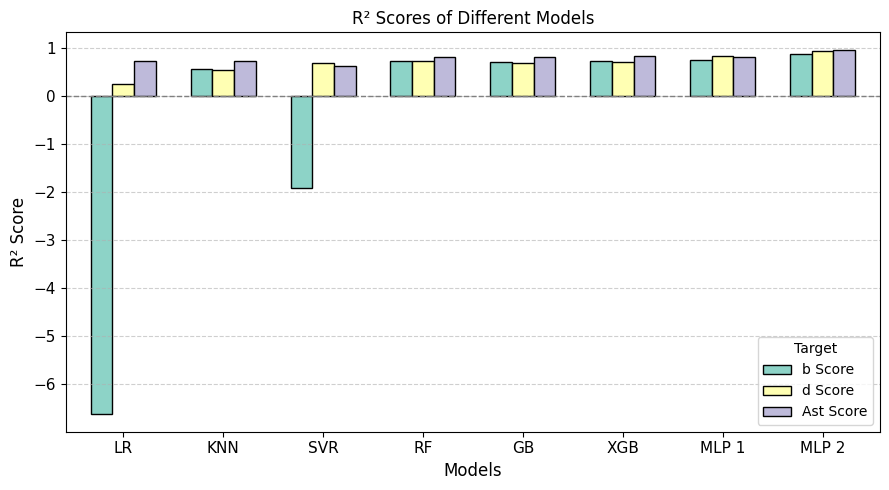

In [ ]:
colors = sns.color_palette("Set3", n_colors=4)

# Plot with improved layout
ax = new_scores.plot(
    kind='bar',
    figsize=(9, 5),
    width=0.65,                     # narrower bars
    color=colors,
    edgecolor='black',
)

# Improve labels and title
plt.title("R² Scores of Different Models", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.xlabel("Models", fontsize=12)

# Horizontal zero line
plt.axhline(y=0, color='gray', linestyle='--', linewidth=1)

# Axis and grid tweaks
plt.xticks(rotation=0, fontsize=11)
plt.yticks(fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend(loc='lower right', fontsize=10, title="Target")

plt.tight_layout()
plt.show()

In [ ]:
# Keep only specific models
selected_models = ["KNN", "RF", "GB", "XGB", "MLP 1", "MLP 2"]
scores_subset = new_scores.loc[selected_models]
scores_subset

,b Score,d Score,Ast Score
Model,,,
KNN,0.5486,0.5370,0.7269
RF,0.7198,0.7204,0.8098
GB,0.6953,0.6890,0.8091
XGB,0.7118,0.6935,0.8232
MLP 1,0.7346,0.8295,0.8143
MLP 2,0.8737,0.9307,0.9411


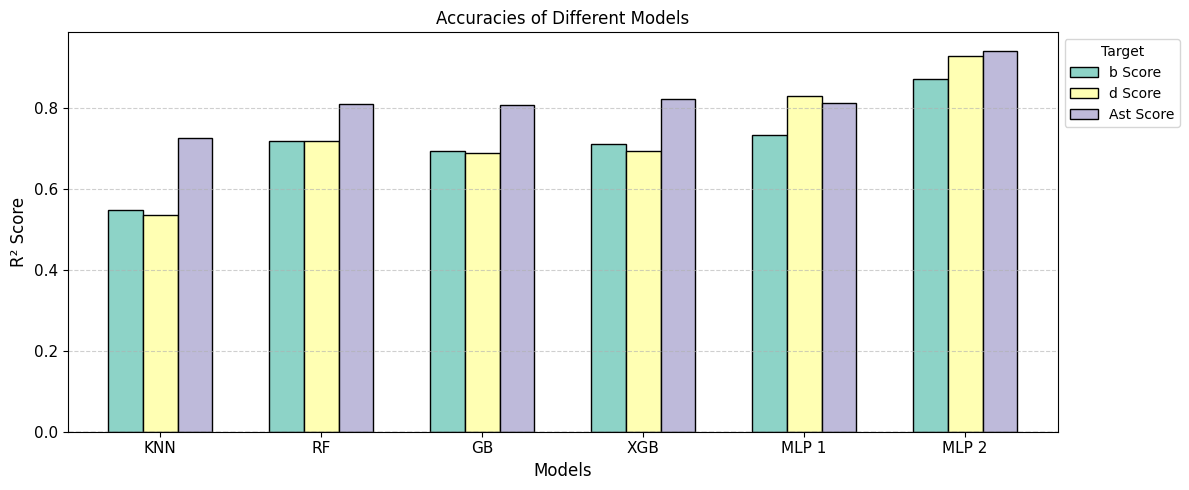

In [ ]:
colors = sns.color_palette("Set3", n_colors=4)

# Plot with improved layout
ax = scores_subset.plot(
    kind='bar',
    figsize=(12, 5),
    width=0.65,                     # narrower bars
    color=colors,
    edgecolor='black',
)

# Improve labels and title
plt.title("Accuracies of Different Models", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.xlabel("Models", fontsize=12)

# Horizontal zero line
plt.axhline(y=0, color='gray', linestyle='--', linewidth=1)

# Axis and grid tweaks
plt.xticks(rotation=0, fontsize=11)
plt.yticks(fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend( fontsize=10, bbox_to_anchor=(1, 1), title="Target")

plt.tight_layout()
plt.show()

In [ ]:
print("Training Mu range:", X_train[:, 2].min(), "to", X_train[:, 2].max())
print("New Mu range:", X_test_new[:, 2].min(), "to", X_test_new[:, 2].max())


Training Mu range: 40 to 1000
New Mu range: 1050 to 1200


#Inference

##Inference with outlier detection

In [ ]:
df = pd.read_csv("ensemble_best_designs_1029.csv")
df_new = pd.read_csv("new_ensemble_best_designs.csv")

In [ ]:
# Take 5 random samples from each
sample_df = df.sample(n=5, random_state=42)
sample_df_new = df_new.sample(n=5, random_state=42)
combined_df = pd.concat([sample_df, sample_df_new], ignore_index=True)
combined_df = combined_df.sample(frac=1, random_state=42).reset_index(drop=True)
combined_df.head()

,fck,fy,Mu,b,d,Ast,algorithm,is_valid,cost,MOR,Mul,utilization,rho,bd_ratio
0,35,550,1175,291,968,3066.8,DE,True,7595.73,1176.182,1242.522,0.9990,0.0109,0.301
1,35,500,920,263,874,2978.3,GA,True,6721.08,921.611,935.371,0.9983,0.0130,0.301
2,35,550,1150,284,946,3116.5,DE,True,7454.99,1152.193,1158.132,0.9981,0.0116,0.300
3,25,550,940,297,987,2441.9,GA,True,7080.73,940.781,941.714,0.9992,0.0083,0.301
4,30,550,1075,294,977,2807.5,DE,True,7394.01,1076.048,1096.098,0.9990,0.0098,0.301


In [ ]:
X_test_sample = combined_df[['fck', 'fy', 'Mu']].values
y_test_sample = combined_df[['b', 'd', 'Ast']].values

In [ ]:
# Define a new input row (must match number of columns)
new_X_row = np.array([[30, 500, 2000]])
new_y_row = np.array([[360, 1200, 4690]])

# Add the new rows
X_test_sample = np.vstack([X_test_sample, new_X_row])
y_test_sample = np.vstack([y_test_sample, new_y_row])

In [ ]:
import joblib
linear_poly = joblib.load('linear_poly.pkl')
rf_pipeline = joblib.load('rf_pipeline.pkl')
gb_pipeline = joblib.load('gb_pipeline.pkl')
best_knn = joblib.load('best_knn.pkl')
best_svr = joblib.load('best_svr.pkl')
mlp_pipeline = joblib.load('mlp_pipeline.pkl')
torch_reg = joblib.load('torch_reg.pkl')
best_xgb = joblib.load('best_xgb.pkl')

In [ ]:
def detect_outliers_and_plot_numpy(model, X_train, X_test, y_test, influential_indices, output_labels=None, model_name="model"):
    """
    Detects outliers in inference samples using Mahalanobis distance and plots predicted vs true values
    for each output dimension, highlighting outliers.

    Parameters:
        model : trained model with .predict()
        X_train : ndarray (n_train, n_features)
        X_test : ndarray (n_test, n_features)
        y_test : ndarray (n_test, n_outputs)
        influential_indices : list of int -> indices of influential input features
        output_labels : list of str -> names of output variables (e.g. ['b', 'd', 'Ast'])
        model_name : str -> name for the plot titles
    """

    # --- Extract influential features ---
    X_train_infl = X_train[:, influential_indices]
    X_test_infl = X_test[:, influential_indices]

    # --- Compute Mahalanobis distance parameters ---
    train_mean = np.mean(X_train_infl, axis=0)
    train_cov = np.cov(X_train_infl, rowvar=False)
    inv_cov = np.linalg.inv(train_cov)

    # --- Threshold (95% confidence) ---
    chi_thresh = np.sqrt(chi2.ppf(0.95, df=X_train_infl.shape[1]))
    print(f"Chi-square distance threshold (95%): {chi_thresh:.2f}\n")

    # --- Predictions ---
    y_pred = model.predict(X_test)


    # --- Detect outliers ---
    outliers, inliers = [], []
    for i, x in enumerate(X_test_infl):
        m_dist = mahalanobis(x, train_mean, inv_cov)
        if m_dist > chi_thresh:
            outliers.append(i)
            print(f"Outlier detected (index {i}) → Mahalanobis Distance: {m_dist:.2f}")
        else:
            inliers.append(i)

    outliers = np.array(outliers)
    inliers = np.array(inliers)

    # --- Handle multi-output labels ---
    if output_labels is None:
        output_labels = [f"Output {i+1}" for i in range(y_test.shape[1])]

    # --- Plot for each output ---
    for j, col in enumerate(output_labels):
        plt.figure(figsize=(6, 4))
        plt.scatter(inliers, y_pred[inliers, j], color='blue', alpha=0.8, label="Predicted (Inliers)")
        plt.scatter(inliers, y_test[inliers, j], color='cyan', alpha=0.8, label="True (Inliers)")

        if len(outliers) > 0:
            plt.scatter(outliers, y_pred[outliers, j], color='red', alpha=0.8, label="Predicted (Outliers)")
            plt.scatter(outliers, y_test[outliers, j], color='orange', alpha=0.8, label="True (Outliers)")

        plt.xlabel("Sample Index")
        plt.ylabel(col)
        plt.title(f"{model_name} — Predicted vs True ({col})")
        plt.grid(alpha=0.3)
        plt.legend(fontsize=8)
        plt.tight_layout()
        plt.show()


In [ ]:
def detect_outliers_and_plot_numpy(model, X_train, X_test, y_test, influential_indices, output_labels=None, model_name="model"):
    """
    Detects outliers in inference samples using Mahalanobis distance, plots predicted vs true values
    for each output dimension (highlighting outliers), and returns a DataFrame with outlier percentage differences.
    """

    # --- Extract influential features ---
    X_train_infl = X_train[:, influential_indices]
    X_test_infl = X_test[:, influential_indices]

    # --- Compute Mahalanobis distance parameters ---
    train_mean = np.mean(X_train_infl, axis=0)
    train_cov = np.cov(X_train_infl, rowvar=False)
    inv_cov = np.linalg.inv(train_cov)

    # --- Threshold (95% confidence) ---
    chi_thresh = np.sqrt(chi2.ppf(0.95, df=X_train_infl.shape[1]))
    print(f"Chi-square distance threshold (95%): {chi_thresh:.2f}\n")

    # --- Predictions ---
    y_pred = model.predict(X_test)

    # --- Detect outliers ---
    outliers, inliers = [], []
    mahalanobis_dists = {}

    for i, x in enumerate(X_test_infl):
        m_dist = mahalanobis(x, train_mean, inv_cov)
        if m_dist > chi_thresh:
            outliers.append(i)
            mahalanobis_dists[i] = m_dist
            print(f"Outlier detected (index {i}) → Mahalanobis Distance: {m_dist:.2f}")
        else:
            inliers.append(i)

    outliers = np.array(outliers)
    inliers = np.array(inliers)

    # --- Handle multi-output labels ---
    if output_labels is None:
        output_labels = [f"Output {i+1}" for i in range(y_test.shape[1])]

    # --- Plot for each output ---
    for j, col in enumerate(output_labels):
        plt.figure(figsize=(6, 4))
        plt.scatter(inliers, y_pred[inliers, j], color='blue', alpha=0.8, label="Predicted (Inliers)")
        plt.scatter(inliers, y_test[inliers, j], color='cyan', alpha=0.8, label="Actual (Inliers)")

        if len(outliers) > 0:
            plt.scatter(outliers, y_pred[outliers, j], color='red', alpha=0.8, label="Predicted (Outliers)")
            plt.scatter(outliers, y_test[outliers, j], color='orange', alpha=0.8, label="Actual (Outliers)")

        plt.xlabel("Sample Index")
        plt.ylabel(col)
        # plt.title(f"{model_name} — Predicted vs True ({col})")
        plt.grid(alpha=0.3)
        plt.legend()
        plt.tight_layout()
        plt.savefig(f"outlier_{col}.png")
        plt.show()

    # --- Construct Summary DataFrame for Outliers ---
    records = []
    for idx in outliers:
        row = {
            'Sample_Idx': idx,
            'Mahalanobis_Dist': round(mahalanobis_dists[idx], 2)
        }
        for j, col in enumerate(output_labels):
            y_true_val = y_test[idx, j]
            y_pred_val = y_pred[idx, j]
            pct_diff = ((y_pred_val - y_true_val) / y_true_val) * 100

            row[f'{col}_true'] = round(y_true_val, 2)
            row[f'{col}_pred'] = round(y_pred_val, 2)
            row[f'{col}_diff_%'] = round(pct_diff, 2)

        records.append(row)

    df_outliers = pd.DataFrame(records)
    return df_outliers

Chi-square distance threshold (95%): 2.80

Outlier detected (index 10) → Mahalanobis Distance: 5.27


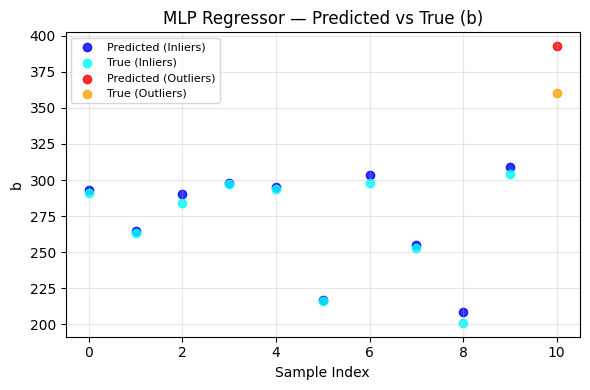

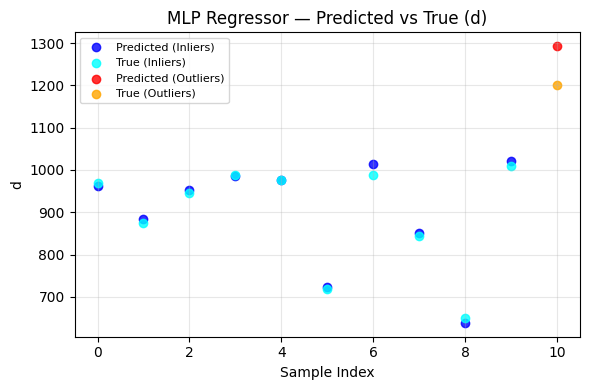

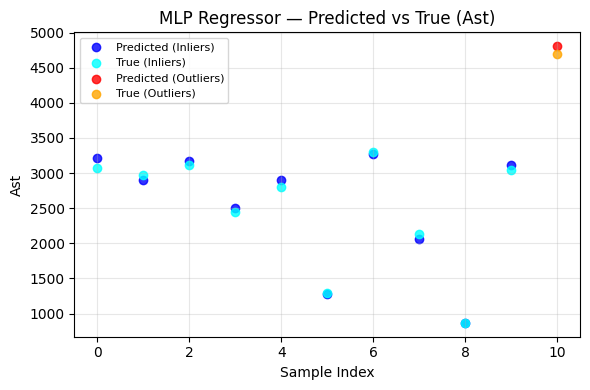

In [ ]:
# Influential feature indices: fck=0, fy=1, Mu=2
influential_indices = [0,1,2]
output_labels = ['b', 'd', 'Ast']

detect_outliers_and_plot_numpy(
    model=mlp_pipeline,        # or GradientBoosting, PyTorch model, etc.
    X_train=X_train,
    X_test=X_test_sample,
    y_test=y_test_sample,
    influential_indices=influential_indices,
    output_labels=output_labels,
    model_name="MLP Regressor"
)


Chi-square distance threshold (95%): 2.80

Outlier detected (index 10) → Mahalanobis Distance: 5.27


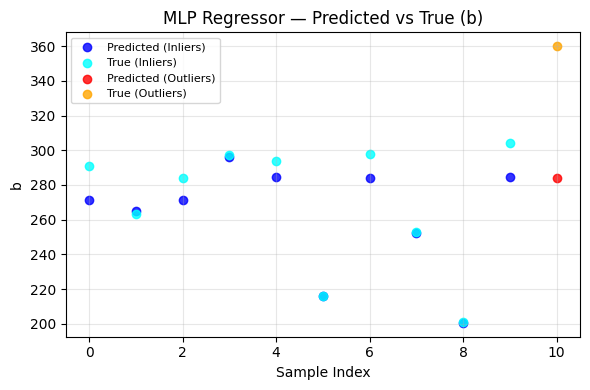

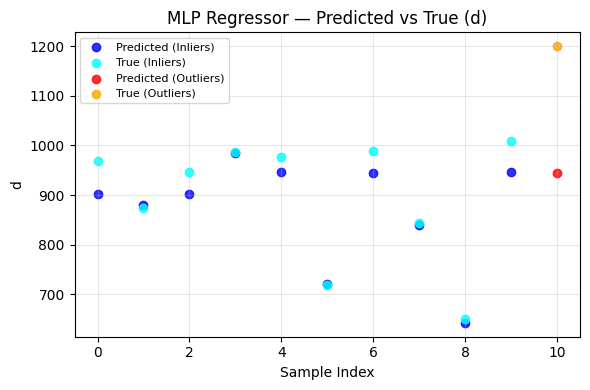

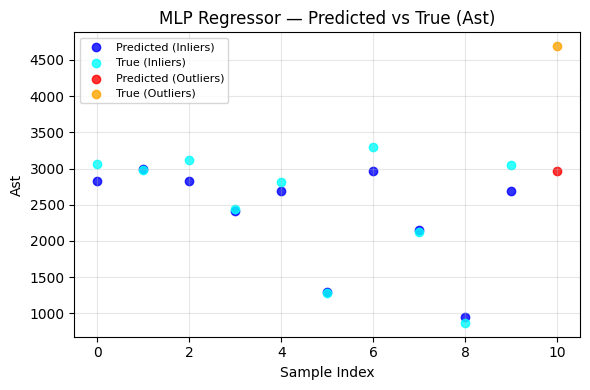

In [ ]:
# Influential feature indices: fck=0, fy=1, Mu=2
influential_indices = [0,1,2]
output_labels = ['b', 'd', 'Ast']

detect_outliers_and_plot_numpy(
    model=rf_pipeline,        # or GradientBoosting, PyTorch model, etc.
    X_train=X_train,
    X_test=X_test_sample,
    y_test=y_test_sample,
    influential_indices=influential_indices,
    output_labels=output_labels,
    model_name="MLP Regressor"
)

Chi-square distance threshold (95%): 2.80

Outlier detected (index 10) → Mahalanobis Distance: 5.27


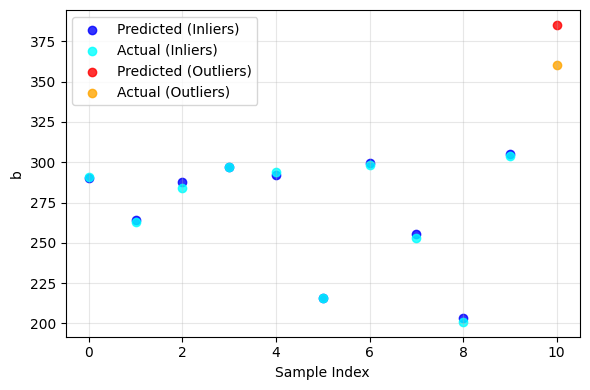

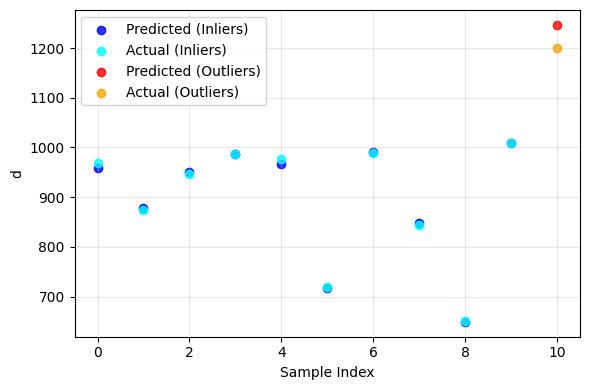

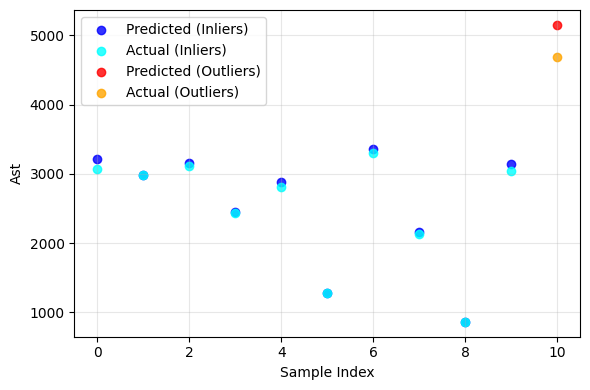

,Sample_Idx,Mahalanobis_Dist,b_true,b_pred,b_diff_%,d_true,d_pred,d_diff_%,Ast_true,Ast_pred,Ast_diff_%
0,10,5.27,360.0,385.170013,6.99,1200.0,1246.880005,3.91,4690.0,5151.700195,9.84


In [ ]:
# Influential feature indices: fck=0, fy=1, Mu=2
influential_indices = [0,1,2]
output_labels = ['b', 'd', 'Ast']

detect_outliers_and_plot_numpy(
    model=torch_reg,        # or GradientBoosting, PyTorch model, etc.
    X_train=X_train,
    X_test=X_test_sample,
    y_test=y_test_sample,
    influential_indices=influential_indices,
    output_labels=output_labels,
    model_name="MLP Regressor"
)

##Inference on single data

In [ ]:
import joblib
# linear_poly = joblib.load('linear_poly.pkl')
# rf_pipeline = joblib.load('rf_pipeline.pkl')
gb_pipeline = joblib.load('gb_pipeline.pkl')
best_knn = joblib.load('best_knn.pkl')
# best_svr = joblib.load('best_svr.pkl')
mlp_pipeline = joblib.load('mlp_pipeline.pkl')
# torch_reg = joblib.load('torch_reg.pkl')
# best_xgb = joblib.load('best_xgb.pkl')

In [ ]:
X = np.array([[40, 500, 200]])

In [ ]:
y = mlp_pipeline.predict(X)
y_safe = correct_invalid_predictions(y, X)
y, y_safe

(array([[ 201.64471308,  521.27774845, 1028.48028924]]),
 array([[ 201.64471308,  521.27774845, 1028.48028924]]))

In [ ]:
y = gb_pipeline.predict(X)
y_safe = correct_invalid_predictions(y, X)
y, y_safe

(array([[ 199.94150273,  495.98487959, 1053.65127489]]),
 array([[ 201.94091775,  500.94472838, 1064.18778764]]))

In [ ]:
y = best_knn.predict(X)
y_safe = correct_invalid_predictions(y, X)
y, y_safe

(array([[ 201. ,  499. , 1067.8]]), array([[ 201. ,  499. , 1067.8]]))

##Comparison with Prakash et al

In [ ]:
import joblib
mlp_pipeline = joblib.load('mlp_pipeline.pkl')
torch_reg = joblib.load('torch_reg.pkl')


###Example 1

In [ ]:
X = np.array([[20, 415, 200]])
y = torch_reg.predict(X)
y_safe = correct_invalid_predictions(y, X)
y_safe

array([[ 200.13609314,  624.20946655, 1088.88628052]])

In [ ]:
get_cost(y[0][0], y[0][1], y[0][2])    #cost by MLP2

np.float32(3064.12)

In [ ]:
get_cost(y_safe[0][0], y_safe[0][1], y_safe[0][2])    #cost by MLP2

np.float64(3070.59)

In [ ]:
get_cost(200.3, 600.9, 1149.7)    #cost of Prakash et al

3068.92

In [ ]:
get_cost(201,618,1102.3)    #from database

3074.7

###Example 2

In [ ]:
X = np.array([[30, 500, 500]])
y = torch_reg.predict(X)
y_safe = correct_invalid_predictions(y, X)
y_safe

array([[ 226.22124,  752.2899 , 1903.3119 ]], dtype=float32)

In [ ]:
get_cost(y[0][0], y[0][1], y[0][2])    #cost by MLP2

np.float32(4644.5)

In [ ]:
get_cost(y_safe[0][0], y_safe[0][1], y_safe[0][2])    #cost by MLP2

np.float32(4644.5)

In [ ]:
get_cost(240.5, 721.4, 1964)    #cost of Prakash et al

4760.89

In [ ]:
get_cost(225, 750, 1886.4)    #from database

4604.4

Comparison 2

In [ ]:
import joblib
mlp_pipeline = joblib.load('mlp_pipeline.pkl')
torch_reg = joblib.load('torch_reg.pkl')

In [ ]:
X = np.array([[30, 300, 687.5]])
y = torch_reg.predict(X)
y_safe = correct_invalid_predictions(y, X)
y_safe

array([[ 265.04892578,  878.27111328, 3606.04130859]])

In [ ]:
get_cost(y_safe[0][0], y_safe[0][1], y_safe[0][2]).item()    #cost by MLP2

7454.81

In [ ]:
get_cost(300, 860.6, 3769.9)

8015.82

In [ ]:
is_valid_design(265.04892578,  878.27111328, 3606.04130859, 30, 300, 687.5)

True

In [ ]:
is_valid_design(300, 860.6, 3769.9, 30, 300, 687.5)

True